In [1]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, pandas as pd
from memoria_icm.datos import *
from memoria_icm.graficos import *
from memoria_icm.funciones import *
from memoria_icm.funciones_CIR import *
from scipy.optimize import minimize
from scipy.stats import gaussian_kde

In [15]:
paleta_colores

{'CC': '#0097b2',
 'LA': '#ffb039',
 'general': '#008fd6',
 'general2': '#009ead',
 'E': '#ff7f0e',
 'R': '#1f77b4'}

In [2]:
df, df_resumen = cargar_datos() #df que lee datos_trackeo contiene solo los analizados!
df = df[(df['especie'] == 'CC') & (df['tratamiento'] == 'R')]
variable = 'r'
df = estimar_sigma_CIR(df, variable)
df = estimar_alpha_mu_CIR(df, variable) #en estos dos cálculos se eliminan las filas que tienen valores 0, el dataframe pierde 192 filas que corresponden a t = 0
df['salinidad'] = df['salinidad'].astype(str)

Datos cargados. Trackeo: (44324, 28), Resumen: (192, 42)


In [3]:
df[df['id'] == 82]

,index,id,t,x,y,id_ubicacion,especie,tratamiento,salinidad,nombre_archivo,...,v_angular,a_angular,theta_v,curvatura,duracion_video_recortada,nivel_salinidad,sigma2_hat,sigma_hat,alpha_hat,mu_hat
14989,14989,82,0.050677,1.583845,-0.242188,1,CC,R,60,Video_005,...,-26.800353,518.685468,-2.820570,102.595635,11.515,alta,0.005909,0.076872,-0.13465,-0.058607
14990,14990,82,0.097654,1.583259,-0.242363,1,CC,R,60,Video_005,...,-4.071152,244.103237,2.753139,2926.579167,11.515,alta,0.005909,0.076872,-0.13465,-0.058607
14991,14991,82,0.154411,1.583387,-0.241810,1,CC,R,60,Video_005,...,-6.655933,42.264661,1.269659,464.793974,11.515,alta,0.005909,0.076872,-0.13465,-0.058607
14992,14992,82,0.209142,1.583513,-0.241535,1,CC,R,60,Video_005,...,0.291237,96.672115,-0.345570,0.000000,11.515,alta,0.005909,0.076872,-0.13465,-0.058607
14993,14993,82,0.245072,1.583694,-0.241738,1,CC,R,60,Video_005,...,3.050845,24.829965,-0.790396,903.120250,11.515,alta,0.005909,0.076872,-0.13465,-0.058607
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15213,15213,82,11.306590,1.883980,-0.089760,1,CC,R,60,Video_005,...,0.835300,1.745306,1.890455,7.368724,11.515,alta,0.005909,0.076872,-0.13465,-0.058607
15214,15214,82,11.376170,1.876175,-0.062442,1,CC,R,60,Video_005,...,0.984856,-0.710596,1.912647,5.846535,11.515,alta,0.005909,0.076872,-0.13465,-0.058607
15215,15215,82,11.426290,1.870321,-0.048782,1,CC,R,60,Video_005,...,0.845987,1.391378,2.222228,32.740040,11.515,alta,0.005909,0.076872,-0.13465,-0.058607
15216,15216,82,11.465770,1.861540,-0.040977,1,CC,R,60,Video_005,...,1.030355,2.817997,2.113097,34.008744,11.515,alta,0.005909,0.076872,-0.13465,-0.058607


## Filtro para dejar pasar un instante de tiempo (número fijo de filas)

In [4]:
n_filas_a_eliminar = 30

df_filtrado = (
    df.groupby('id', group_keys=False, observed=True)
      .apply(lambda x: x.iloc[n_filas_a_eliminar:])
)

df_filtrado

df = df_filtrado

C:\Users\franc\AppData\Local\Temp\ipykernel_6224\4247245743.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.iloc[n_filas_a_eliminar:])


## Prueba de los métodos con una trayectoria simulada

Figura guardada en: C:\Users\franc\Desktop\Para informe\trayectorias de prueba simuladas\trayectoria_simulada_CIR.png
alpha_hat: 1.0077556073042866
r_infinito_hat: 0.5069891127734177
sigma_hat: 0.3065224500511943


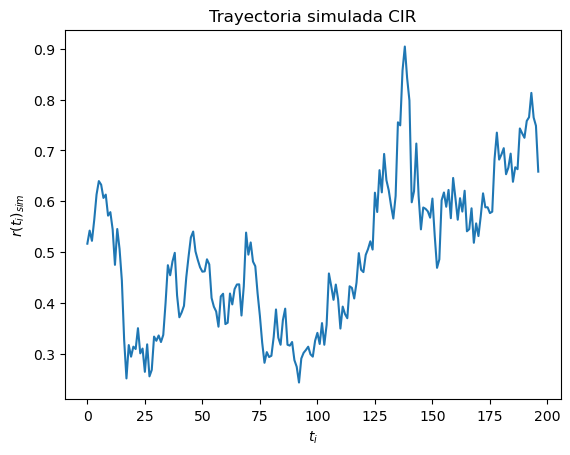

In [18]:
#simulación de prueba para ver si los métodos se portan bien
np.random.seed(150)
dt = 0.05
trayectorias_df, ids_df = extraer_trayectorias(df, variable)
longitud_minima_comun = min(len(r) for r, _ in trayectorias_df) - 1

r0_vals = np.array([r[0] for r, _ in trayectorias_df])
kde_r0 = gaussian_kde(r0_vals)
x_grid = np.linspace(min(r0_vals), max(r0_vals), 1000)
pdf_vals  = kde_r0(x_grid)
pdf_vals /= pdf_vals.sum() #normalizar

def sample_r0():
            return np.random.choice(x_grid, p = pdf_vals)

r0_sim = sample_r0()
alpha = 1.2
r_infinito = 0.5
sigma = 0.3

r_sim = simular_CIR(longitud_minima_comun, dt, alpha, r_infinito, sigma, r0_sim)
plt.plot(r_sim, color = paleta_colores['R'])
plt.title('Trayectoria simulada CIR')
plt.grid(visible = False)
plt.ylabel(r'$r(t_i)_{sim}$')
plt.xlabel(r'$t_i$')
guardar_figura('trayectoria_simulada_CIR', 'trayectorias de prueba simuladas')

#cálculo de sigma por variación cuadrática
dr = np.diff(r_sim)              # Δrₖ = rₖ₊₁ − rₖ
numerador = np.sum(dr**2)        # Σ (Δrₖ)²
denominador = np.sum(r_sim[:-1] * dt)  # Σ rₖ * Δt
sigma2_hat = np.nan
if denominador > 0:
    sigma2_hat = numerador / denominador
sigma_hat = np.sqrt(sigma2_hat) if np.isfinite(sigma2_hat) else np.nan

#cálculo de alpha y r_infinito mediante OLS - fórmula del paper
df_tmp = pd.DataFrame({'r': r_sim, 't': np.arange(len(r_sim)) * dt, 'id': 'sim'})
df_out = estimar_alpha_mu_CIR(df_tmp, variable)
alpha_hat = df_out[df_out['id'] == 'sim']['alpha_hat'].iloc[0]
r_infinito_hat    = df_out[df_out['id'] == 'sim']['mu_hat'].iloc[0]

print(f"alpha_hat: {alpha_hat}")
print(f"r_infinito_hat: {r_infinito_hat}")
print(f"sigma_hat: {sigma_hat}")

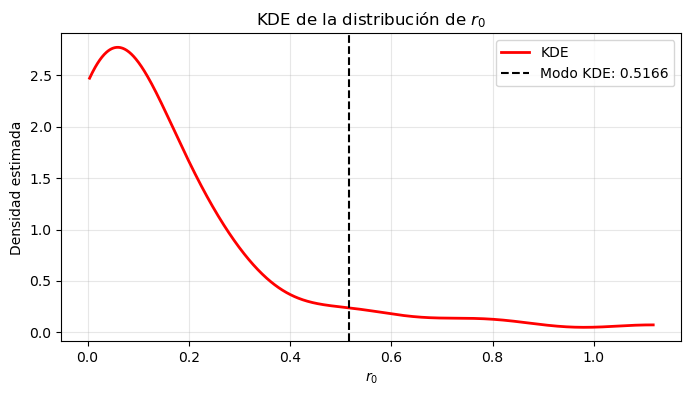

In [19]:
dens = kde_r0(x_grid)
r0_mode = r0_sim

plt.figure(figsize=(8, 4))
plt.plot(x_grid, dens, color='red', lw=2, label='KDE')
plt.axvline(
    r0_mode,
    color='black',
    linestyle='--',
    lw=1.5,
    label=f'Modo KDE: {r0_mode:.4f}'
)
plt.xlabel(r"$r_0$")
plt.ylabel("Densidad estimada")
plt.title(r"KDE de la distribución de $r_0$")
plt.legend()
plt.grid(alpha=0.3)
#guardar_figura('KDE_r0', 'trayectorias de prueba simuladas')
plt.show()


In [20]:
#con Bessel primero
initial_guess = [alpha_hat, r_infinito_hat]

res_bessel = minimize(
    fun=logverosimilitud_CIR_Bessel,
    x0=initial_guess,
    args=(r_sim, dt, sigma_hat),
    method='Nelder-Mead'
)

#resultados
params_opt_bessel = res_bessel.x
func_val_opt_bessel = res_bessel.fun
success_bessel = res_bessel.success
message_bessel = res_bessel.message

# Comparación con valores reales
params_real = np.array([alpha, r_infinito])
error_abs_bessel = np.abs(params_opt_bessel - params_real)
error_rel_bessel = error_abs_bessel / params_real

# Mostrar resultados
print("Parámetros estimados:      ", params_opt_bessel)
print("Parámetros reales:         ", params_real)
print("Error absoluto:            ", error_abs_bessel)
print("Error relativo (%):        ", 100 * error_rel_bessel)
print("Valor función objetivo:    ", func_val_opt_bessel)
print("¿Convergió exitosamente?:  ", success_bessel)
print("Mensaje del optimizador:   ", message_bessel)


Parámetros estimados:       [1.02358601 0.50713518]
Parámetros reales:          [1.2 0.5]
Error absoluto:             [0.17641399 0.00713518]
Error relativo (%):         [14.70116597  1.42703507]
Valor función objetivo:     -324.395917302905
¿Convergió exitosamente?:   True
Mensaje del optimizador:    Optimization terminated successfully.


In [21]:
#con ncx2

res_ncx2 = minimize(
    fun=logverosimilitud_CIR_ncx2,
    x0=initial_guess,
    args=(r_sim, dt, sigma_hat),
    method='Nelder-Mead'
)

#resultados
params_opt_ncx2 = res_ncx2.x
func_val_opt_ncx2 = res_ncx2.fun
success_ncx2 = res_ncx2.success
message_ncx2 = res_ncx2.message

# Comparación con valores reales
error_abs_ncx2 = np.abs(params_opt_ncx2 - params_real)
error_rel_ncx2 = error_abs_ncx2 / params_real

# Mostrar resultados
print("Parámetros estimados:      ", params_opt_ncx2)
print("Parámetros reales:         ", params_real)
print("Error absoluto:            ", error_abs_ncx2)
print("Error relativo (%):        ", 100 * error_rel_ncx2)
print("Valor función objetivo:    ", func_val_opt_ncx2)
print("¿Convergió exitosamente?:  ", success_ncx2)
print("Mensaje del optimizador:   ", message_ncx2)

Parámetros estimados:       [1.02358601 0.50713518]
Parámetros reales:          [1.2 0.5]
Error absoluto:             [0.17641399 0.00713518]
Error relativo (%):         [14.70116597  1.42703507]
Valor función objetivo:     -324.3959173029051
¿Convergió exitosamente?:   True
Mensaje del optimizador:    Optimization terminated successfully.


Con los métodos testeados y funcionando, pasamos a repetir esto mismo (con un poco más de complejidad) para cada grupo especie-tratamiento-salinidad.

In [22]:
# #acá solo testeamos qué porcentaje de los parámetros son válidos, pero no eliminamos nada
# df_filtrado = df[(df['alpha_hat'] > 0) &
#     (df['mu_hat'] > 0) &
#     (df['sigma_hat'] > 0) &
#     (~df['alpha_hat'].isna()) & 
#     (~df['mu_hat'].isna()) &
#     (~df['sigma_hat'].isna())]

# ids_total = df['id'].nunique()
# ids_filtrados = df_filtrado['id'].unique()
# descartadas = ids_total - ids_filtrados
# porc_descartado = 100 * descartadas / ids_total

# print(f"Trayectorias totales:         {ids_total}")
# print(f"Trayectorias válidas:         {ids_filtrados}")
# print(f"Trayectorias descartadas:     {descartadas}")
# print(f"Porcentaje descartado:        {porc_descartado:.2f}%")
# print(ids_filtrados)

In [23]:
# df = df_filtrado
# df

# Aplicación a los grupos

## Optimización y visualización

In [24]:
###PLOT 3D
import warnings
warnings.filterwarnings('ignore')

resultados_todos = []
trayectorias_all = {}

grupos = df[['especie', 'tratamiento', 'salinidad']].drop_duplicates().to_records(index=False)

for especie, tratamiento, salinidad in grupos:
    df_grp = filtrar_grupo_salinidad(df, especie, tratamiento, salinidad)
    trayectorias, ids = extraer_trayectorias(df_grp, variable)

    parametros_grupo = (
        df_grp.groupby('id')[['alpha_hat', 'mu_hat', 'sigma_hat']]
        .first()
        .reset_index()
    )

    parametros_grupo[['alpha_hat', 'mu_hat']] = parametros_grupo[['alpha_hat', 'mu_hat']].clip(lower=1e-10)
    
    ids_filtrados, trayectorias_filtradas = zip(*[
        (i, t) for i, t in zip(ids, trayectorias)
        if i in parametros_grupo['id'].values
    ])
    
    for id_tray, (data, dt) in zip(ids_filtrados, trayectorias_filtradas):
        trayectorias_all[id_tray] = (data, dt)

    param_dict = parametros_grupo.set_index('id')[['alpha_hat', 'mu_hat', 'sigma_hat']].to_dict('index')

    resultados = []
    for id_tray, (data, dt) in zip(ids_filtrados, trayectorias_filtradas):
        sigma = param_dict[id_tray]['sigma_hat']
        x0 = np.array((param_dict[id_tray]['alpha_hat'], param_dict[id_tray]['mu_hat']))

        puntos = []
        def wrapped_cost(x):
            val = logverosimilitud_CIR_Bessel(x, data, dt, sigma)
            puntos.append((x.copy(), val))
            return val

        res = minimize(
            fun=wrapped_cost,
            x0=x0,
            method='Nelder-Mead',
        )

        alpha, mu = res.x
        
        resultados.append({
            'id':            id_tray,
            'alpha':         alpha,
            'mu':            mu,
            'sigma':         sigma,
            'valor_funcion': res.fun,
            'exito':         res.success,
            'mensaje':       res.message,
            'r0':            data[0]})
        

        alpha_list = [p[0][0] for p in puntos]
        mu_list   = [p[0][1] for p in puntos]

        alpha_min = min(alpha_list)
        alpha_max = max(alpha_list)
        mu_min    = min(mu_list)
        mu_max    = max(mu_list)

        epsilon_alpha = max(0.2 * (alpha_max - alpha_min), 1e-3)
        epsilon_mu    = max(0.2 * (mu_max - mu_min), 1e-3)

        alpha_min -= epsilon_alpha
        alpha_max += epsilon_alpha
        mu_min    -= epsilon_mu
        mu_max    += epsilon_mu

        alpha_vals = np.linspace(alpha_min, alpha_max, 50)
        mu_vals    = np.linspace(mu_min, mu_max, 50)
        
        # #2D
        # A_grid, M_grid = np.meshgrid(alpha_vals, mu_vals)
        # Z = np.zeros_like(A_grid)

        # for i in range(A_grid.shape[0]):
        #     for j in range(A_grid.shape[1]):
        #         params = [A_grid[i, j], M_grid[i, j]]
        #         Z[i, j] = logverosimilitud_CIR_Bessel(params, data, dt, sigma)
        
        # plt.figure(figsize=(8, 6))
        # contour = plt.contourf(A_grid, M_grid, Z, levels=50, cmap='viridis')
        # plt.colorbar(contour, label=r"$\log(L)$")
        
        # points = np.array([p for p, _ in puntos])        
        # plt.plot(points[:, 0], points[:, 1], marker='o', color='red', markersize=3, linewidth=1, label="Trayectoria")
        # plt.scatter(x0[0], x0[1], color='white', edgecolor = 'black', s=100, label="Punto inicial")
        # plt.scatter(alpha, mu, color='gold', edgecolor = 'black', s=100, label="Mínimo encontrado")

        # plt.xlabel(r'$\alpha$')
        # plt.ylabel(r'$r_\infty$')
        # plt.title(f"{especie}-{tratamiento}-{salinidad} - id: {id_tray}")
        # plt.legend()
        # guardar_figura(f"{especie}-{tratamiento}-{salinidad}-{id_tray}", 'opti2D_FINAL')
        # plt.show()

        # # 3D
        # from mpl_toolkits.mplot3d import Axes3D
        # from matplotlib import cm

        # fig = plt.figure(figsize=(10, 8))
        # ax = fig.add_subplot(111, projection='3d')

        # # Superficie de la función de verosimilitud
        # surf = ax.plot_surface(A_grid, M_grid, Z, cmap=cm.viridis,
        #                        linewidth=0, antialiased=True, alpha=0.6)

        # # Trayectoria de la optimización
        # puntos_trayectoria_x = [p[0][0] for p in puntos]
        # puntos_trayectoria_y = [p[0][1] for p in puntos]
        # puntos_trayectoria_z = [p[1] for p in puntos]
        # ax.plot(puntos_trayectoria_x, puntos_trayectoria_y, puntos_trayectoria_z,
        #         marker='o', color='red', markersize=3, linestyle='-', linewidth=2, label="Trayectoria")

        # # Punto inicial
        # ax.scatter(x0[0], x0[1], wrapped_cost(x0), color='white', edgecolor= 'black', s=100, zorder=5, label="Punto inicial")

        # # Mínimo encontrado
        # ax.scatter(alpha, mu, res.fun, color='gold', edgecolor = 'black', s=100, zorder=5, label="Mínimo encontrado")
        # ax.set_xlabel(r'$\alpha$')
        # ax.set_ylabel(r'$r_\infty$')
        # ax.set_title(f"{especie}-{tratamiento}-{salinidad} - id: {id_tray}")
        # fig.colorbar(surf, shrink=0.5, aspect=5)
        # ax.legend()
        # guardar_figura(f"{especie}-{tratamiento}-{salinidad}-{id_tray}", 'opti3D_FINAL')
        # plt.show()

    df_res = pd.DataFrame(resultados)
    df_res['grupo'] = f"{especie}-{tratamiento}-{salinidad}"
    resultados_todos.append(df_res)

df_todos = pd.concat(resultados_todos, ignore_index=True)

In [25]:
df_todos

,id,alpha,mu,sigma,valor_funcion,exito,mensaje,r0,grupo
0,42,4.952006e-01,4.099496e-02,0.066046,-865.621632,True,Optimization terminated successfully.,0.071869,CC-R-35-N
1,43,3.607137e-02,3.971088e-02,0.038007,-966.579560,True,Optimization terminated successfully.,0.011874,CC-R-35-N
2,45,1.150000e-10,9.750000e-11,0.063726,-745.082752,True,Optimization terminated successfully.,0.018991,CC-R-35-N
3,46,2.143573e-02,1.094494e-05,0.040605,-848.792353,True,Optimization terminated successfully.,0.126780,CC-R-35-N
4,48,2.707092e-01,4.552205e-02,0.077767,-816.102086,True,Optimization terminated successfully.,0.012293,CC-R-35-R
5,50,4.757879e-02,9.681821e-01,0.022493,-961.236327,True,Optimization terminated successfully.,0.118141,CC-R-35-R
6,51,1.000000e-10,1.000000e-10,0.028659,-871.241261,True,Optimization terminated successfully.,0.052971,CC-R-35-R
7,52,5.797367e-01,2.824205e-01,0.028046,-922.694735,True,Optimization terminated successfully.,0.164442,CC-R-35-R
8,53,6.631861e-02,5.031487e-01,0.154795,-538.825498,True,Optimization terminated successfully.,0.173656,CC-R-35-R
9,54,1.169360e-03,1.132447e+01,0.039117,-850.674025,False,Maximum number of function evaluations has bee...,0.155432,CC-R-40


## De acá en adelante es sobre un grupo particular

In [26]:
import warnings
warnings.filterwarnings('ignore')

grupo = 'CC-R'

filtro = df_todos[df_todos['grupo'].str.startswith(grupo)].copy()
filtro['salinidad'] = filtro['grupo'].str[5:]
orden_salinidad = sorted(filtro['salinidad'].unique(), key=lambda x: str(x))
filtro['salinidad_ordenada'] = pd.Categorical(filtro['salinidad'], categories=orden_salinidad, ordered=True)

In [27]:
filtro

,id,alpha,mu,sigma,valor_funcion,exito,mensaje,r0,grupo,salinidad,salinidad_ordenada
0,42,4.952006e-01,4.099496e-02,0.066046,-865.621632,True,Optimization terminated successfully.,0.071869,CC-R-35-N,35-N,35-N
1,43,3.607137e-02,3.971088e-02,0.038007,-966.579560,True,Optimization terminated successfully.,0.011874,CC-R-35-N,35-N,35-N
2,45,1.150000e-10,9.750000e-11,0.063726,-745.082752,True,Optimization terminated successfully.,0.018991,CC-R-35-N,35-N,35-N
3,46,2.143573e-02,1.094494e-05,0.040605,-848.792353,True,Optimization terminated successfully.,0.126780,CC-R-35-N,35-N,35-N
4,48,2.707092e-01,4.552205e-02,0.077767,-816.102086,True,Optimization terminated successfully.,0.012293,CC-R-35-R,35-R,35-R
5,50,4.757879e-02,9.681821e-01,0.022493,-961.236327,True,Optimization terminated successfully.,0.118141,CC-R-35-R,35-R,35-R
6,51,1.000000e-10,1.000000e-10,0.028659,-871.241261,True,Optimization terminated successfully.,0.052971,CC-R-35-R,35-R,35-R
7,52,5.797367e-01,2.824205e-01,0.028046,-922.694735,True,Optimization terminated successfully.,0.164442,CC-R-35-R,35-R,35-R
8,53,6.631861e-02,5.031487e-01,0.154795,-538.825498,True,Optimization terminated successfully.,0.173656,CC-R-35-R,35-R,35-R
9,54,1.169360e-03,1.132447e+01,0.039117,-850.674025,False,Maximum number of function evaluations has bee...,0.155432,CC-R-40,40,40


Figura guardada en: C:\Users\franc\Desktop\Para informe\plot_parametros_CIR\parametros-CC-R.png


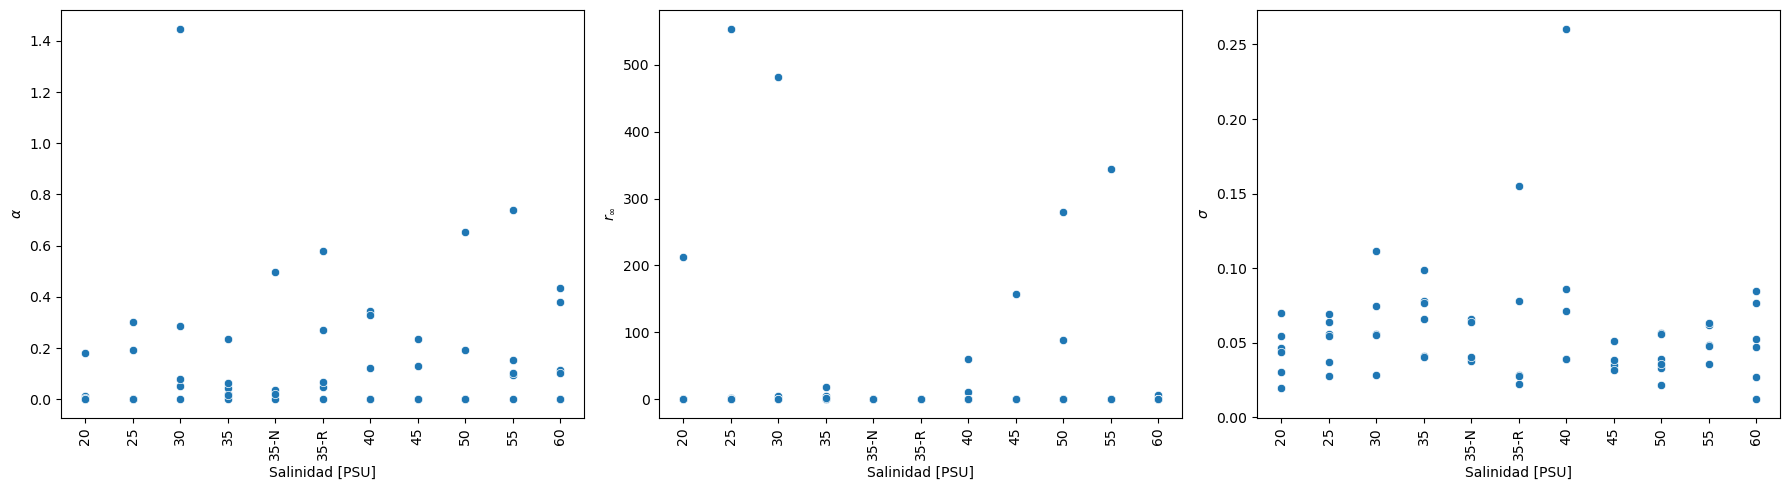

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

#alpha
sns.scatterplot(data=filtro, x='salinidad_ordenada', y='alpha', ax=axs[0])#, hue = 'mejor_por_logL')
axs[0].set_ylabel(r'$\alpha$')
axs[0].set_xlabel('Salinidad [PSU]')

#mu
sns.scatterplot(data=filtro, x='salinidad_ordenada', y='mu', ax=axs[1])#, hue = 'mejor_por_logL')
axs[1].set_ylabel(r'$r_{\infty}$')
axs[1].set_xlabel('Salinidad [PSU]')

#sigma
sns.scatterplot(data=filtro, x='salinidad_ordenada', y='sigma', ax=axs[2])#, hue = 'mejor_por_logL')
axs[2].set_ylabel(r'$\sigma$')
axs[2].set_xlabel('Salinidad [PSU]')

axs[0].tick_params(axis='x', rotation=90)
axs[1].tick_params(axis='x', rotation=90)
axs[2].tick_params(axis='x', rotation=90)

plt.tight_layout()
guardar_figura(f'parametros-{grupo}', 'plot_parametros_CIR')
plt.show()

In [29]:
#para quitar outliers y ver diferencia entre gráficos

def filtrar_outliers_IQR(df, columnas):
    df_filtrado = df.copy()
    for col in columnas:
        Q1 = df_filtrado[col].quantile(0.25)
        Q3 = df_filtrado[col].quantile(0.75)
        IQR = Q3 - Q1
        lim_inf = Q1 - 1.5 * IQR
        lim_sup = Q3 + 1.5 * IQR
        df_filtrado = df_filtrado[(df_filtrado[col] >= lim_inf) & (df_filtrado[col] <= lim_sup)]
    return df_filtrado

filtro_sin_outliers = filtrar_outliers_IQR(filtro, ['alpha', 'mu', 'sigma'])

Figura guardada en: C:\Users\franc\Desktop\Para informe\plot_parametros_CIR_sin_outliers\parametros-CC-R.png


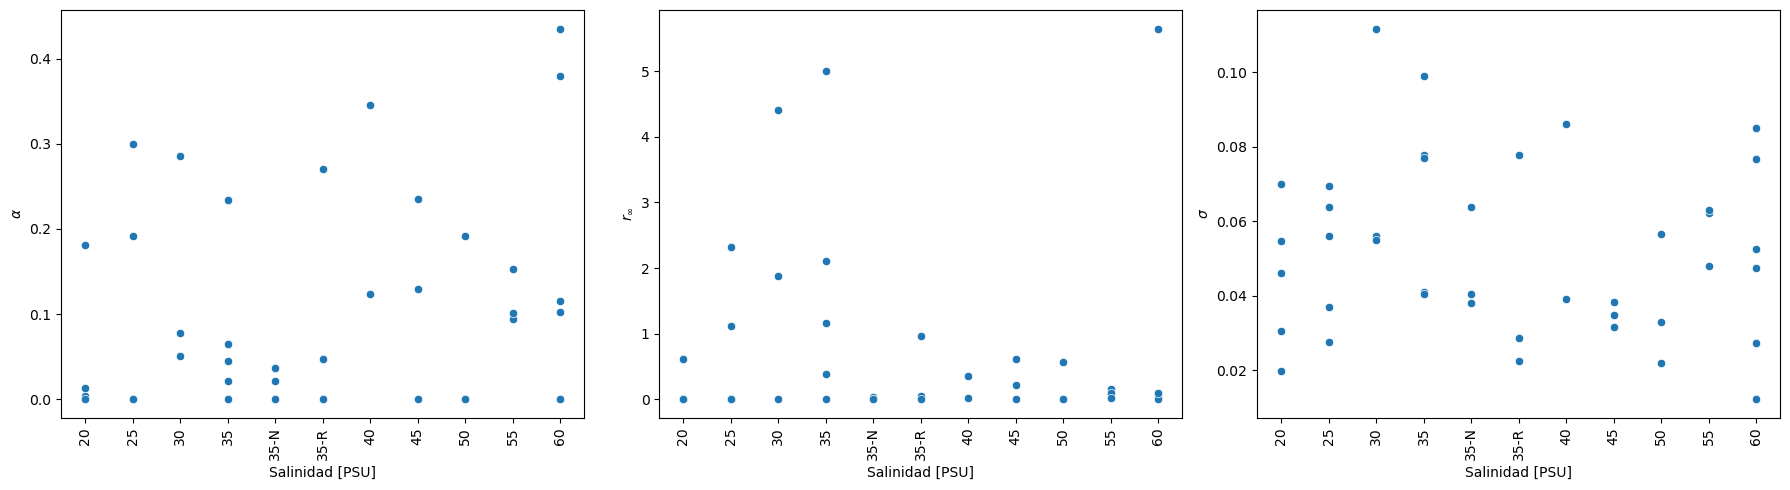

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

# alpha
sns.scatterplot(data=filtro_sin_outliers, x='salinidad_ordenada', y='alpha', ax=axs[0])
axs[0].set_ylabel(r'$\alpha$')
axs[0].set_xlabel('Salinidad [PSU]')

# mu
sns.scatterplot(data=filtro_sin_outliers, x='salinidad_ordenada', y='mu', ax=axs[1])
axs[1].set_ylabel(r'$r_{\infty}$')
axs[1].set_xlabel('Salinidad [PSU]')

# sigma
sns.scatterplot(data=filtro_sin_outliers, x='salinidad_ordenada', y='sigma', ax=axs[2])
axs[2].set_ylabel(r'$\sigma$')
axs[2].set_xlabel('Salinidad [PSU]')

# Rotar las etiquetas del eje x para mejor legibilidad
for ax in axs:
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
guardar_figura(f'parametros-{grupo}', 'plot_parametros_CIR_sin_outliers')
plt.show()

In [31]:
paleta_colores

{'CC': '#0097b2',
 'LA': '#ffb039',
 'general': '#008fd6',
 'general2': '#009ead',
 'E': '#ff7f0e',
 'R': '#1f77b4'}

Figura guardada en: C:\Users\franc\Desktop\Para informe\plot_parametros_CIR\scatter_mu_alpha_CIR.png


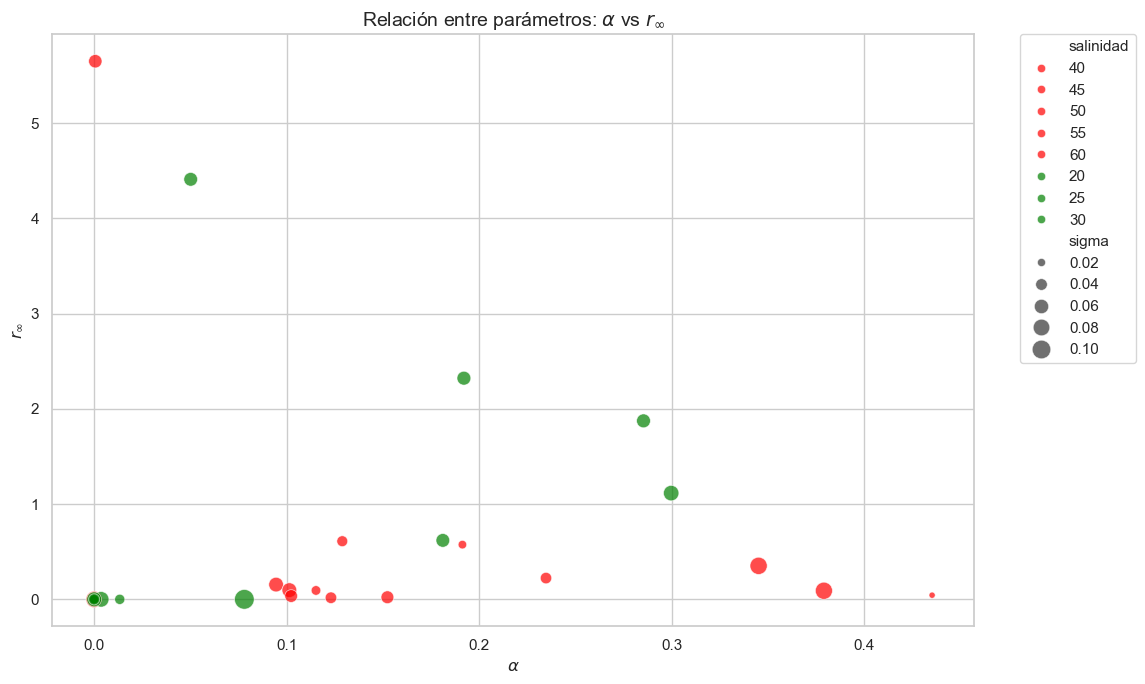

In [32]:

import matplotlib.pyplot as plt
import seaborn as sns

filtrofinal = filtro_sin_outliers[~filtro_sin_outliers['salinidad'].isin(['35', '35-N', '35-R'])]


# Configuración de estilo
sns.set(style="whitegrid")
paleta_salinidad = {
    "35-N": "blue",
    "35-R": "blue",
    "35": "blue",
    "20": "green",
    "25": "green",
    "30": "green",
    "40": "red",
    "45": "red",
    "50": "red",
    "55": "red",
    "60": "red"
}
# Gráfico de dispersión
plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(
    data=filtrofinal,
    x="alpha",
    y="mu",
    hue="salinidad",       # Color por salinidad
    size="sigma",          # Tamaño proporcional a sigma,         # Forma del marcador según éxito
    sizes=(20, 200),       # Rango de tamaños de puntos
    alpha=0.7,
    palette=paleta_salinidad
)

# Ajustes de leyenda y título
plt.title(r"Relación entre parámetros: $\alpha$ vs $r_{\infty}$", fontsize=14)
plt.xlabel(r"$\alpha$", fontsize=12)
plt.ylabel(r"$r_{\infty}$", fontsize=12)
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)  # leyenda afuera
guardar_figura('scatter_mu_alpha_CIR', 'plot_parametros_CIR')
plt.show()


In [33]:
def evaluar_estimadores_CIR_paper_una_trayectoria(simular_CIR, trayectoria, dt, alpha, r_infinito, sigma, variable,
                                                 especie, tratamiento, salinidad, id_actual, M=1000):
    r_vals, dt_tray = trayectoria
    N_rep = len(r_vals) - 1
    r0 = r_vals[0]
    
    sims = np.stack([simular_CIR(N_rep, dt, alpha, r_infinito, sigma, r0) for _ in range(M)])
    percentiles = [np.percentile(sims, q, axis=0) for q in (0, 5, 50, 95, 100)]
    p0, p5, p50, p95, p100 = percentiles
    times = np.arange(N_rep + 1) * dt

    puntos_dentro_banda = (r_vals >= p5) & (r_vals <= p95)
    
    conteo_dentro = np.sum(puntos_dentro_banda)
    conteo_total = len(r_vals)
    porcentaje_dentro = (conteo_dentro / conteo_total) * 100
    print(f"Grupo {especie}-{tratamiento}-{salinidad.upper()} - Porcentaje de tiempo dentro de la banda de 90%: {porcentaje_dentro:.2f}%")
    
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.fill_between(times, p0, p100, color='lightgray', alpha=0.4, label='0–100% simuladas')
    ax.fill_between(times, p5, p95, color='lightblue', alpha=0.4, label='Banda 90% simulada')
    ax.plot(times, p50, 'b-', linewidth=2, label='Mediana simulada')
    ax.plot(times, p5, '--', color='red', lw=1.5, label='5º percentil')
    ax.plot(times, p95, '--', color='blue', lw=1.5, label='95º percentil')

    r_trunc = r_vals[:N_rep + 1]
    t_tray = np.arange(len(r_trunc)) * dt_tray
    ax.plot(t_tray, r_trunc, color='black', linewidth=1.5, alpha=0.9, label=f"Trayectoria real")

    ax.legend(loc='upper right')
    ax.set_xlabel("Tiempo [s]")
    ax.set_ylabel(variable)
    ax.set_title(f"Grupo {especie}-{tratamiento}-{salinidad.upper()}")
    ax.grid(True, alpha=0.3)
    guardar_figura(f'SIM_{especie}-{tratamiento}-{salinidad} - ID-{id_actual}', f'simulaciones_CIR_{especie}-{tratamiento}_FINAL')
    plt.show()

    return porcentaje_dentro

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 85.07%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-42.png


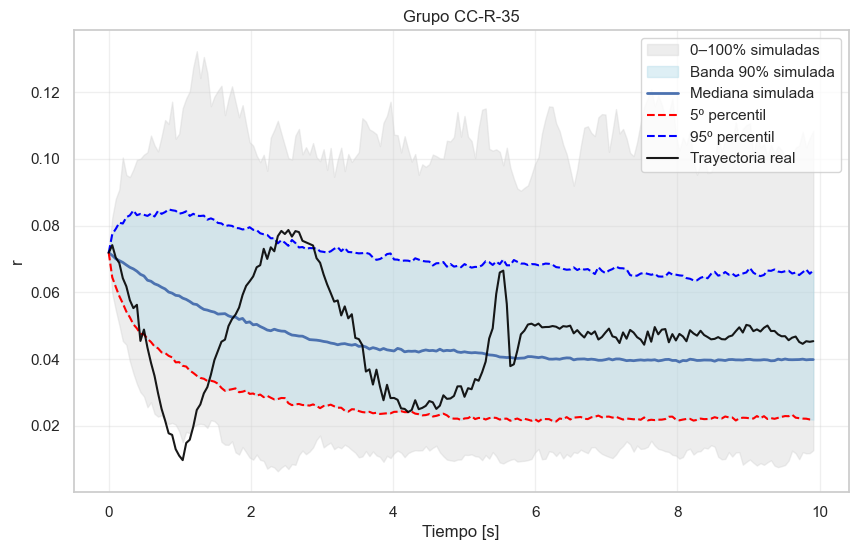

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 93.56%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-43.png


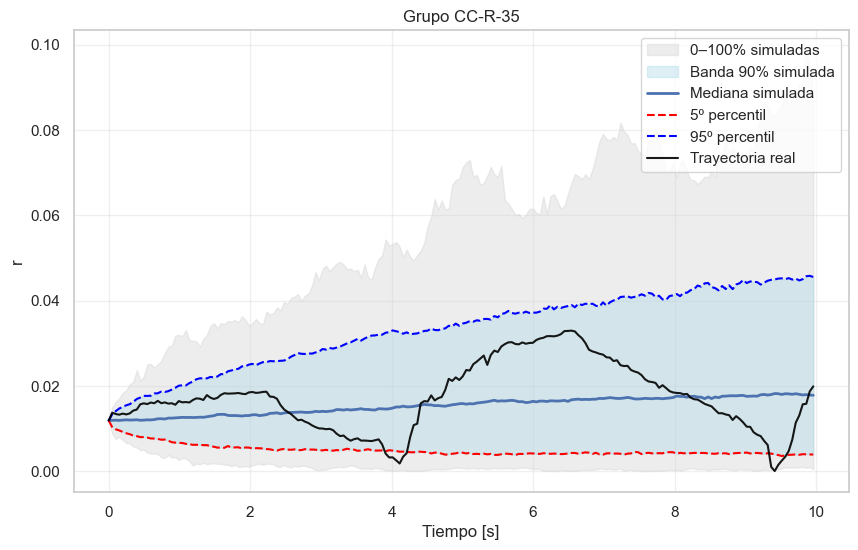

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 16.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-45.png


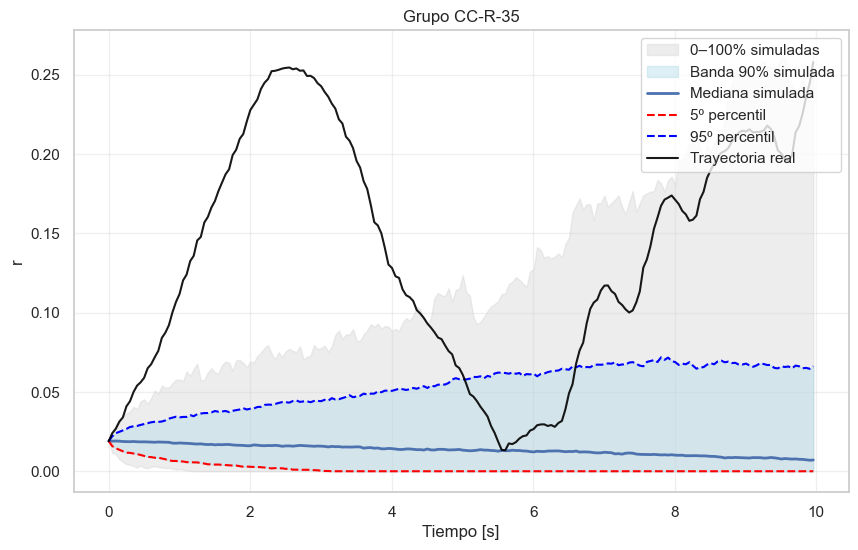

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 34.67%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-46.png


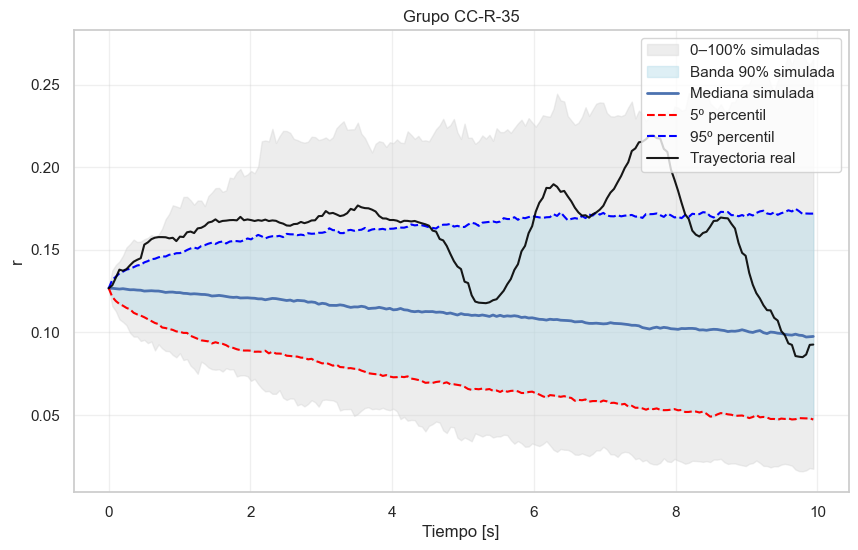

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 90.05%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-48.png


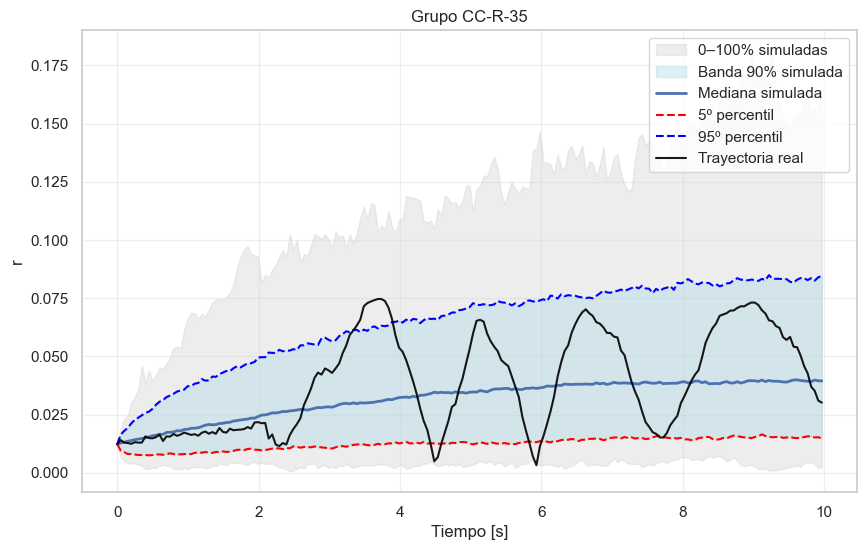

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 65.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-50.png


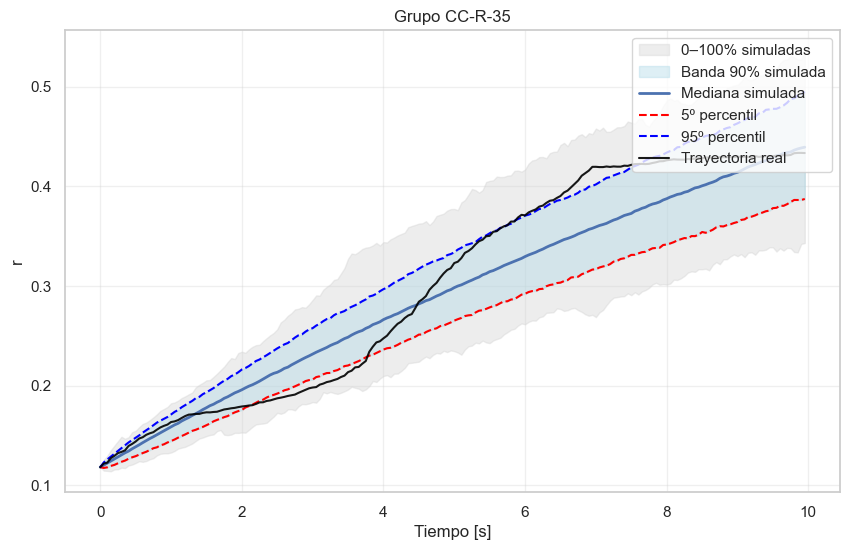

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 0.99%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-51.png


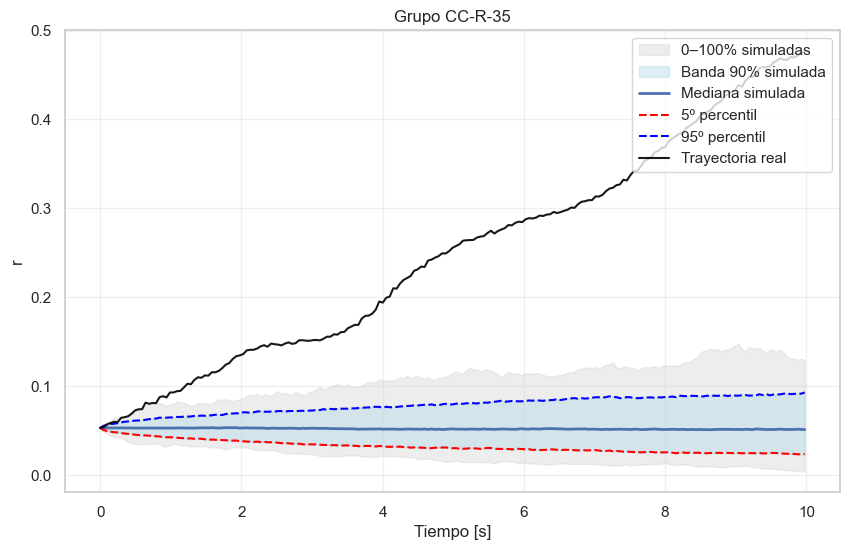

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 87.56%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-52.png


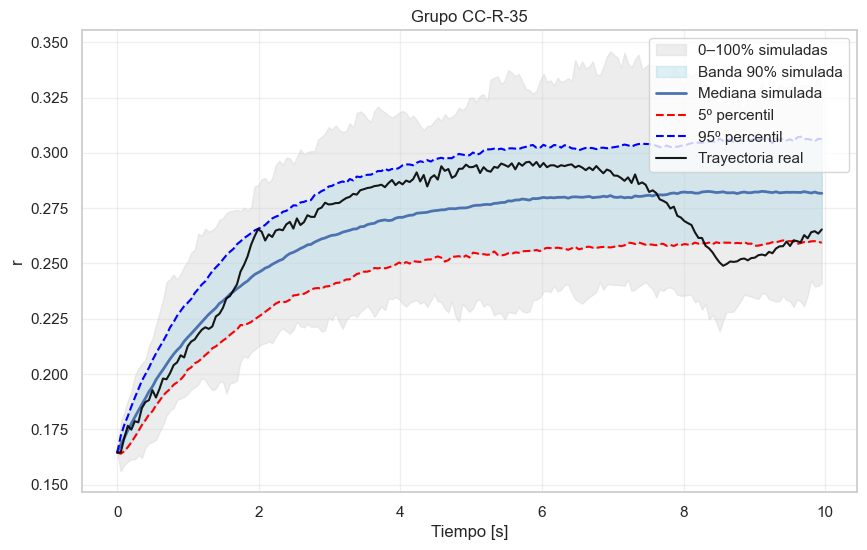

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 89.95%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-53.png


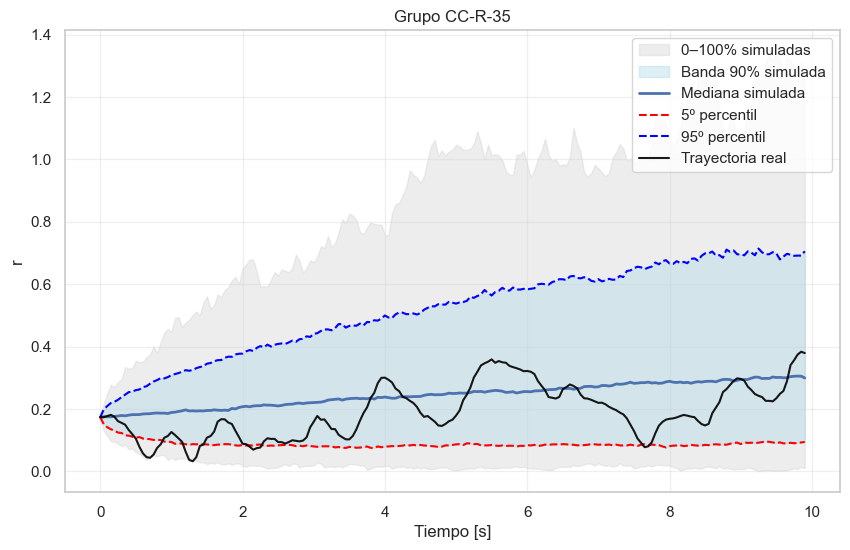

Grupo CC-R-40 - Porcentaje de tiempo dentro de la banda de 90%: 93.97%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-40 - ID-54.png


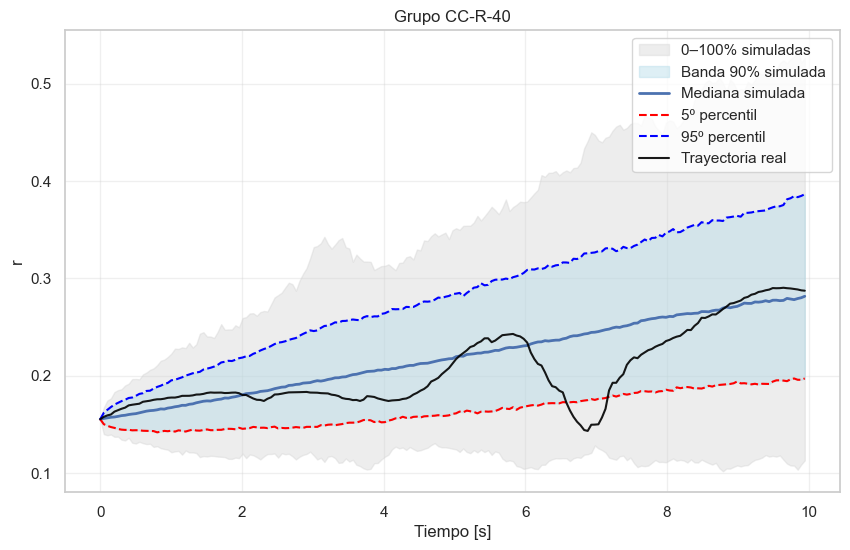

Grupo CC-R-40 - Porcentaje de tiempo dentro de la banda de 90%: 79.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-40 - ID-55.png


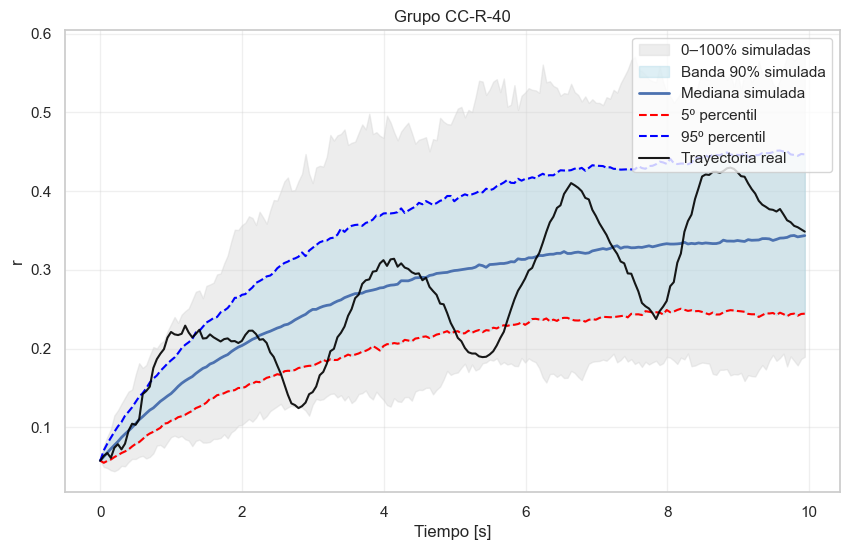

Grupo CC-R-40 - Porcentaje de tiempo dentro de la banda de 90%: 72.14%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-40 - ID-57.png


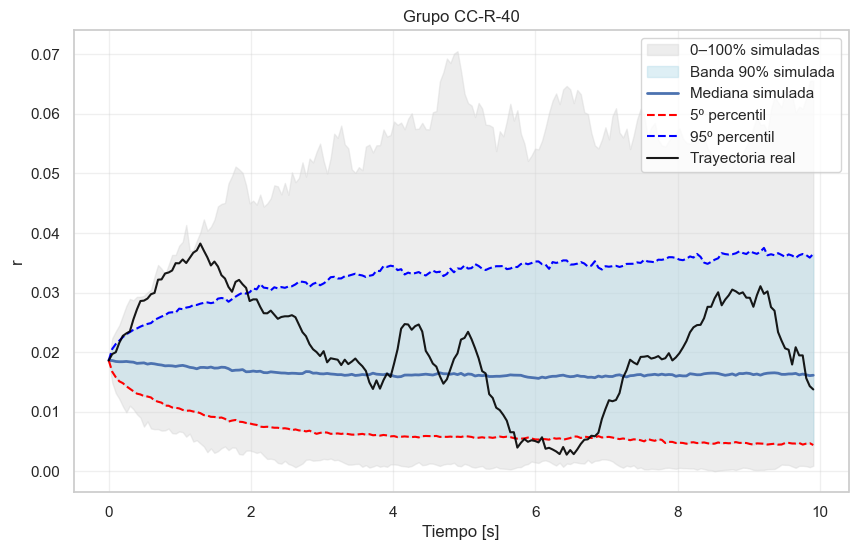

Grupo CC-R-40 - Porcentaje de tiempo dentro de la banda de 90%: 81.09%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-40 - ID-58.png


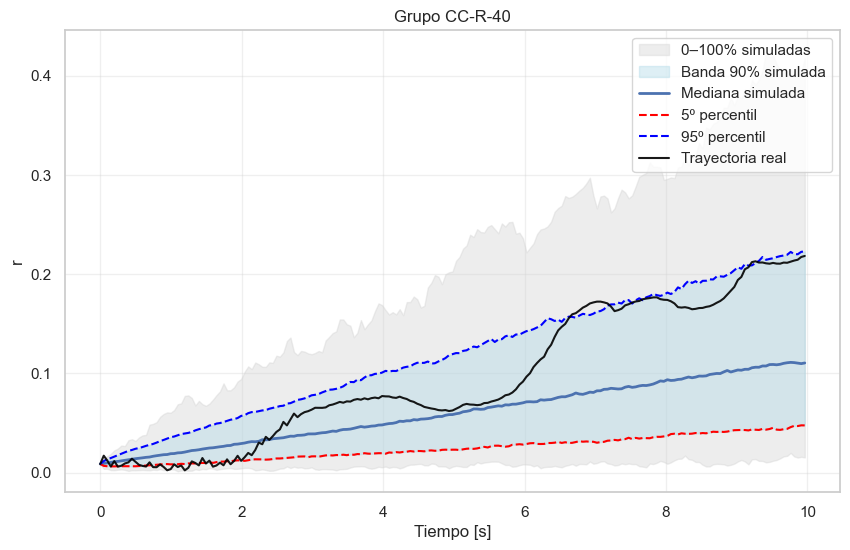

Grupo CC-R-40 - Porcentaje de tiempo dentro de la banda de 90%: 74.37%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-40 - ID-59.png


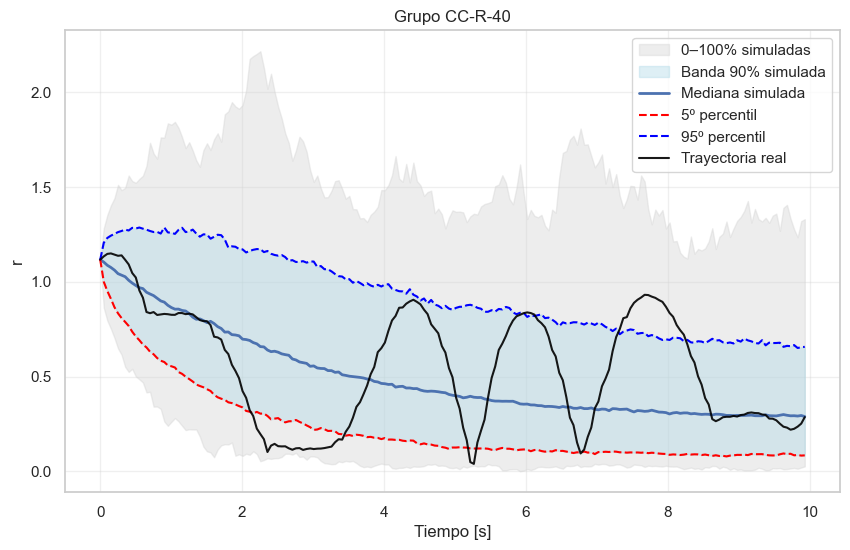

Grupo CC-R-45 - Porcentaje de tiempo dentro de la banda de 90%: 64.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-45 - ID-60.png


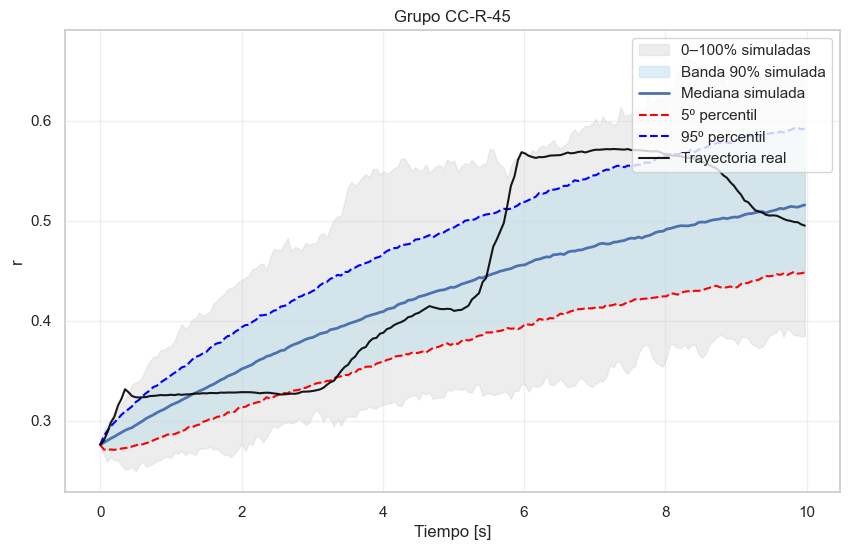

Grupo CC-R-45 - Porcentaje de tiempo dentro de la banda de 90%: 67.17%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-45 - ID-61.png


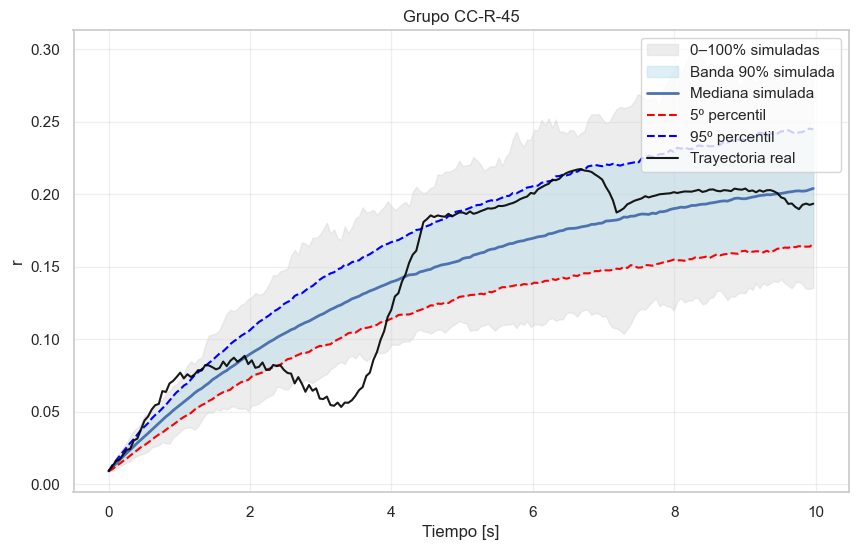

Grupo CC-R-45 - Porcentaje de tiempo dentro de la banda de 90%: 80.60%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-45 - ID-63.png


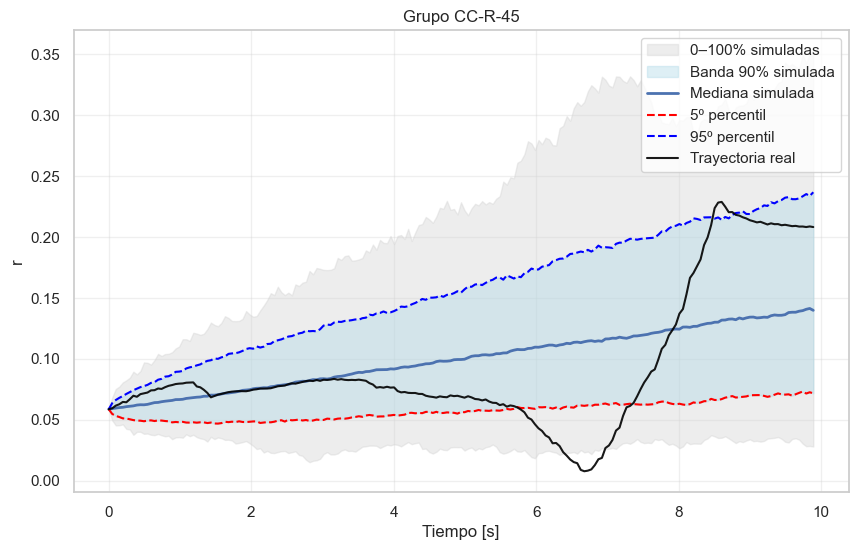

Grupo CC-R-45 - Porcentaje de tiempo dentro de la banda de 90%: 73.10%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-45 - ID-64.png


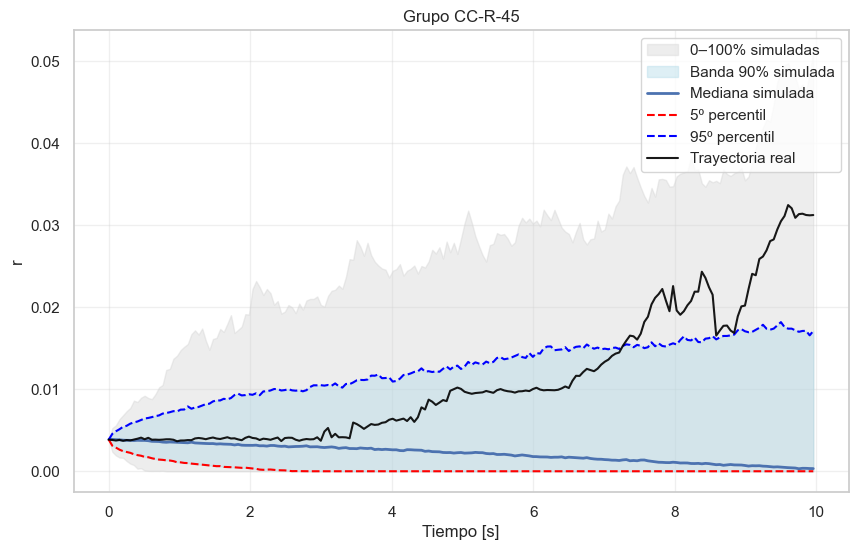

Grupo CC-R-50 - Porcentaje de tiempo dentro de la banda de 90%: 7.96%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-50 - ID-66.png


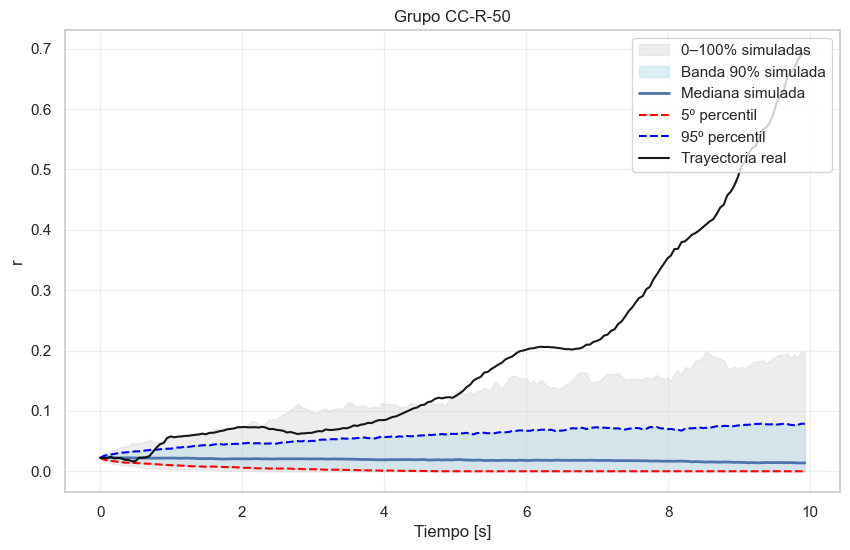

Grupo CC-R-50 - Porcentaje de tiempo dentro de la banda de 90%: 0.50%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-50 - ID-67.png


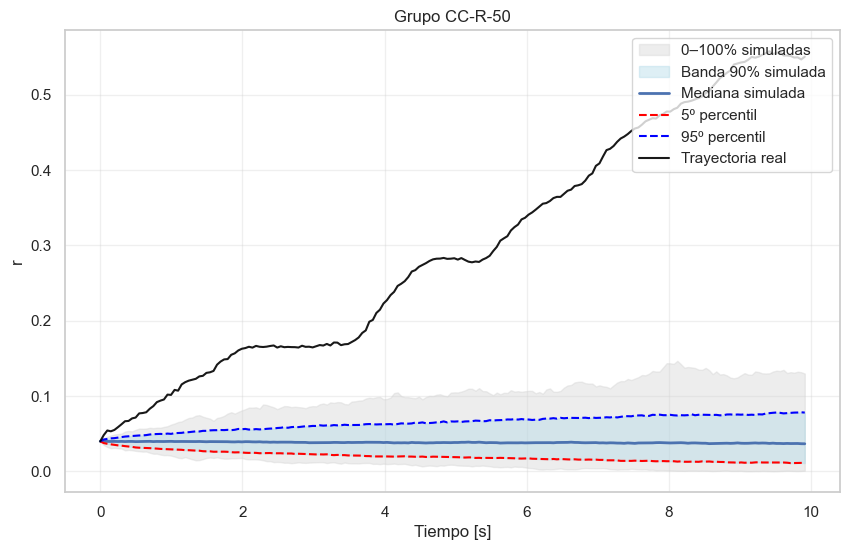

Grupo CC-R-50 - Porcentaje de tiempo dentro de la banda de 90%: 87.50%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-50 - ID-68.png


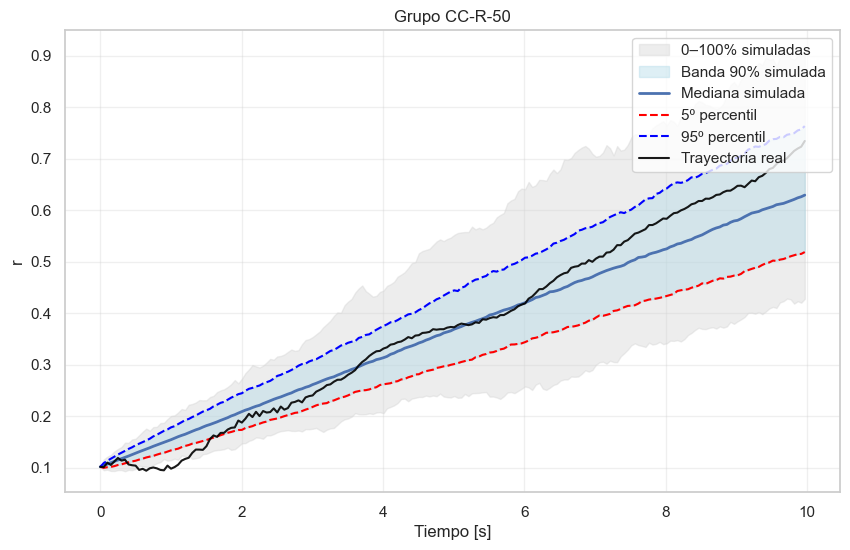

Grupo CC-R-50 - Porcentaje de tiempo dentro de la banda de 90%: 100.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-50 - ID-69.png


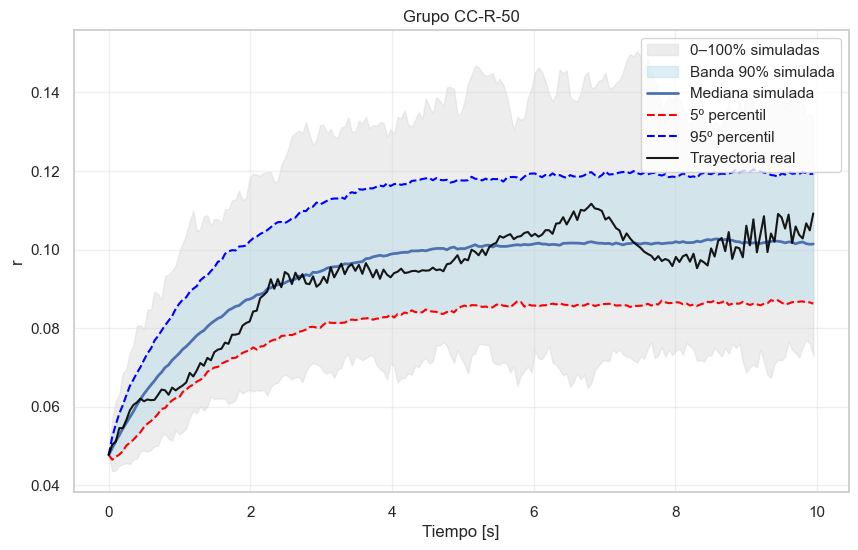

Grupo CC-R-50 - Porcentaje de tiempo dentro de la banda de 90%: 57.87%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-50 - ID-70.png


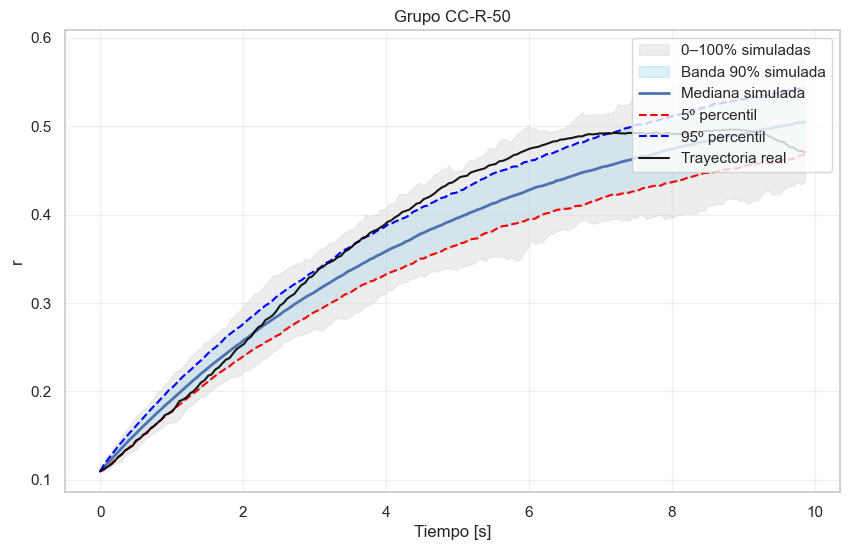

Grupo CC-R-50 - Porcentaje de tiempo dentro de la banda de 90%: 80.71%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-50 - ID-71.png


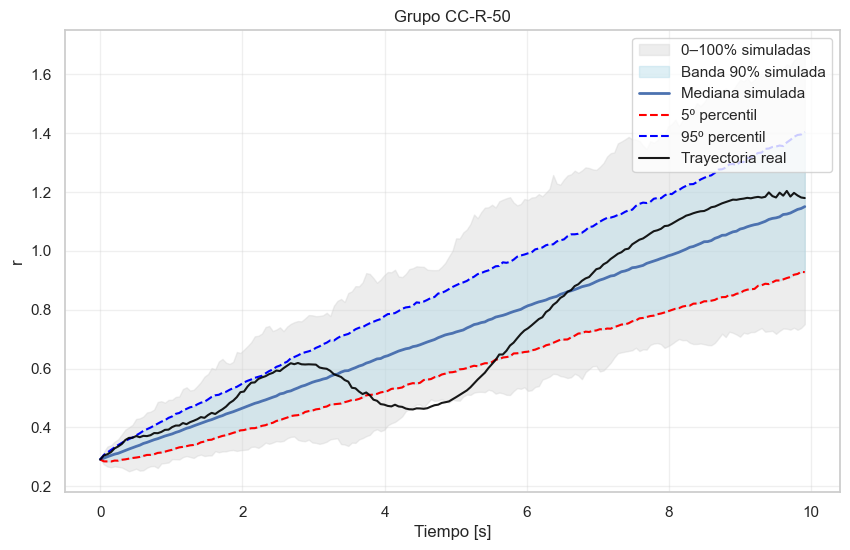

Grupo CC-R-55 - Porcentaje de tiempo dentro de la banda de 90%: 93.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-55 - ID-73.png


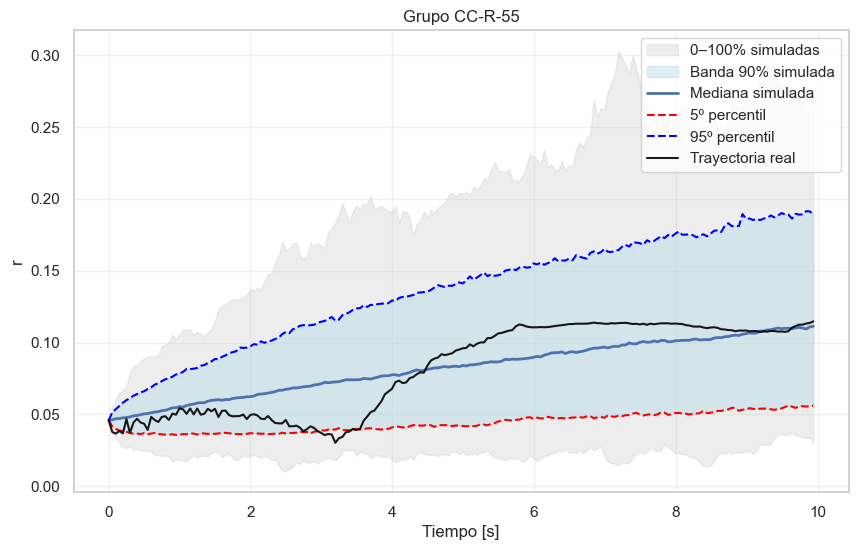

Grupo CC-R-55 - Porcentaje de tiempo dentro de la banda de 90%: 26.87%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-55 - ID-74.png


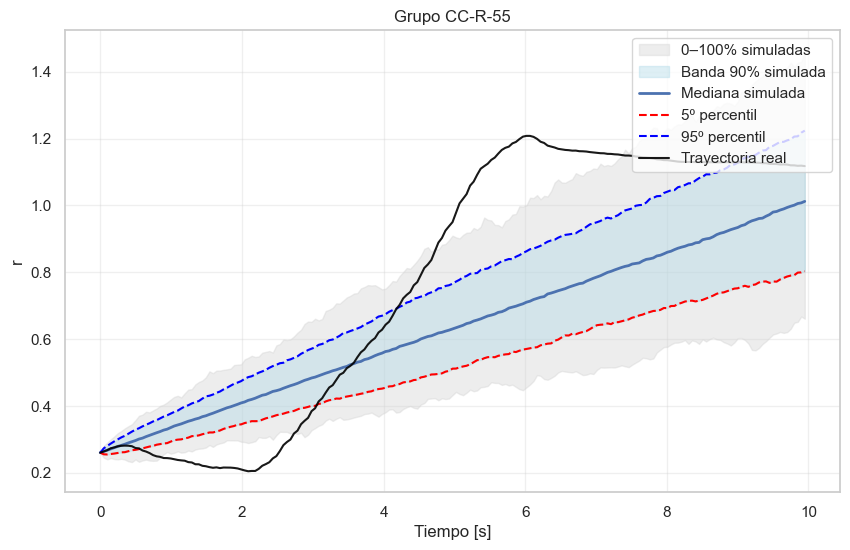

Grupo CC-R-55 - Porcentaje de tiempo dentro de la banda de 90%: 75.38%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-55 - ID-75.png


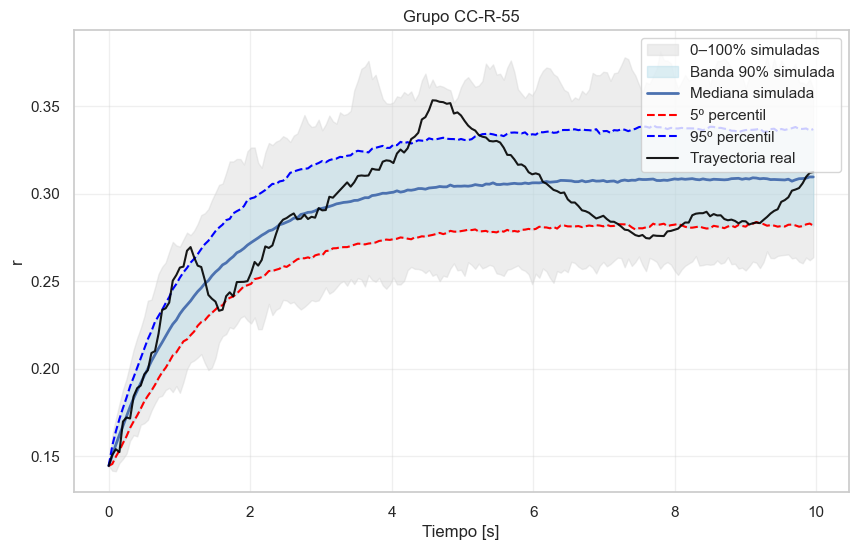

Grupo CC-R-55 - Porcentaje de tiempo dentro de la banda de 90%: 98.49%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-55 - ID-76.png


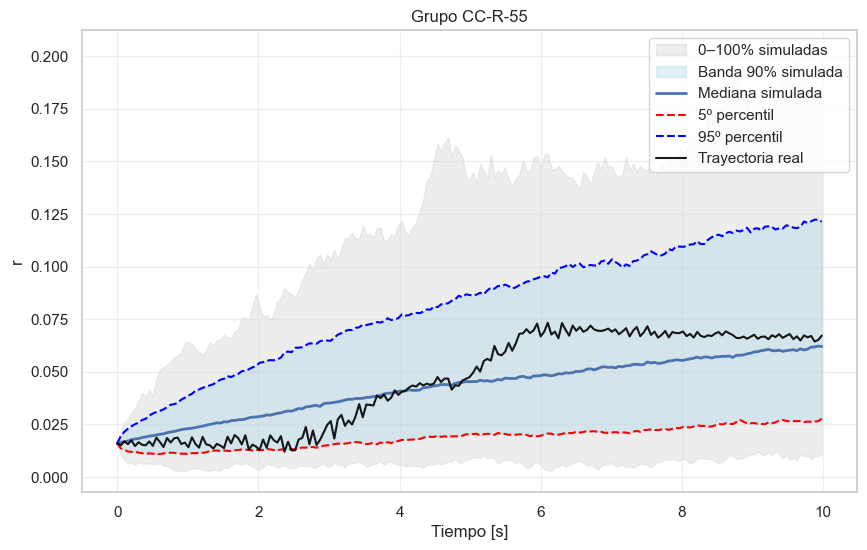

Grupo CC-R-55 - Porcentaje de tiempo dentro de la banda de 90%: 63.32%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-55 - ID-77.png


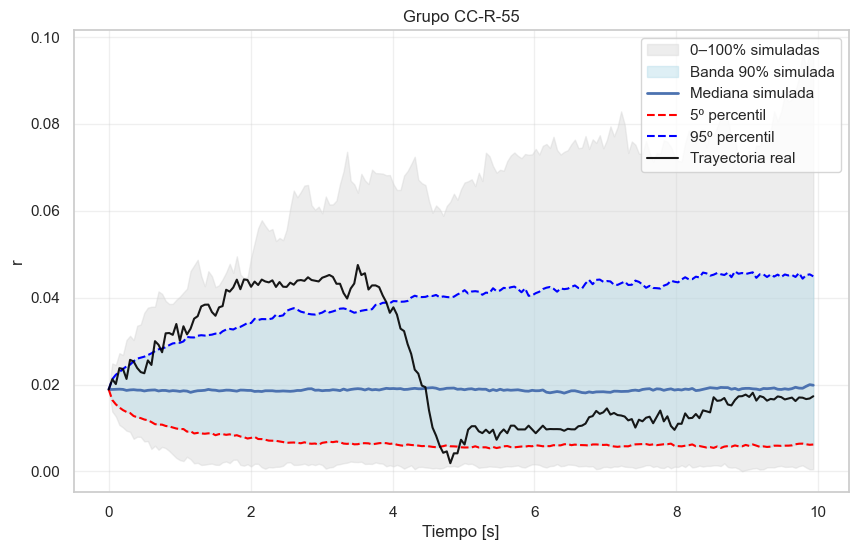

Grupo CC-R-60 - Porcentaje de tiempo dentro de la banda de 90%: 83.08%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-60 - ID-78.png


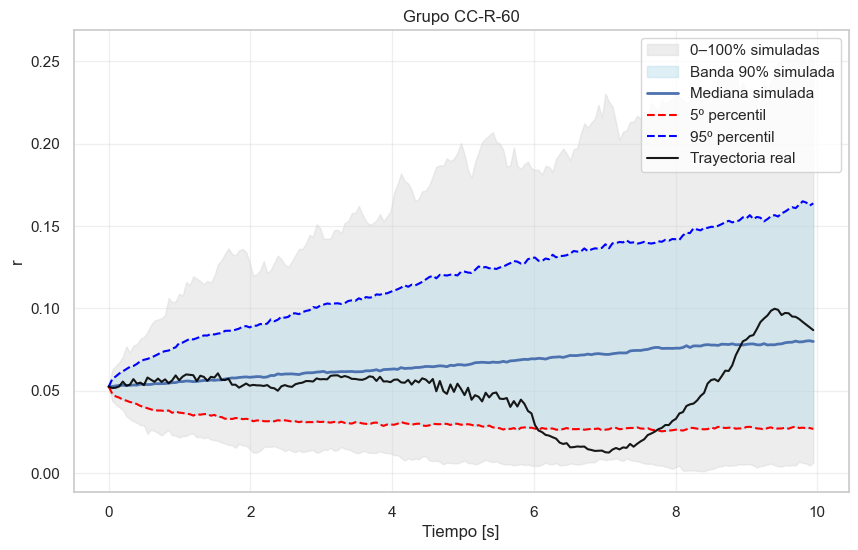

Grupo CC-R-60 - Porcentaje de tiempo dentro de la banda de 90%: 95.52%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-60 - ID-79.png


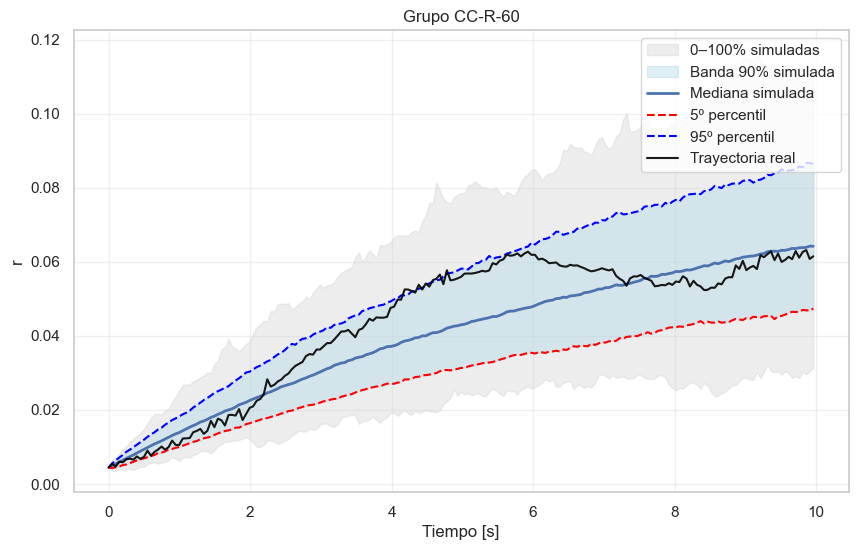

Grupo CC-R-60 - Porcentaje de tiempo dentro de la banda de 90%: 82.91%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-60 - ID-80.png


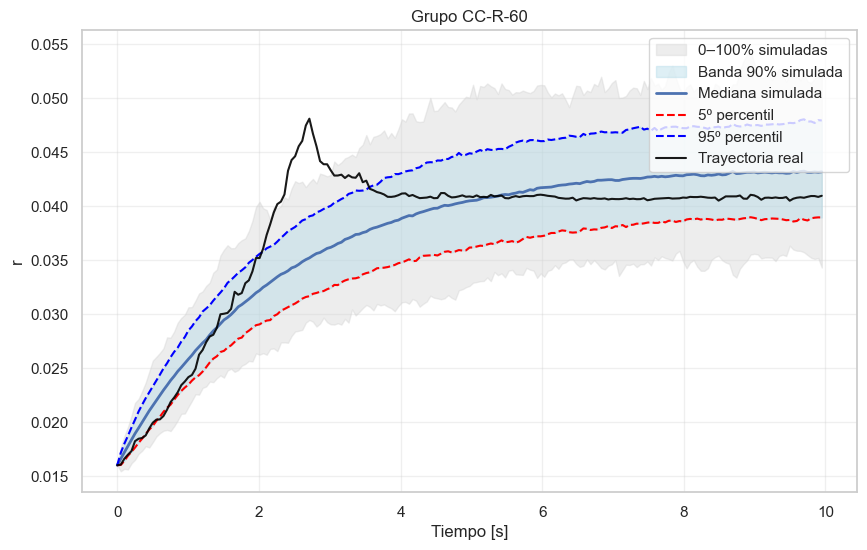

Grupo CC-R-60 - Porcentaje de tiempo dentro de la banda de 90%: 91.96%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-60 - ID-81.png


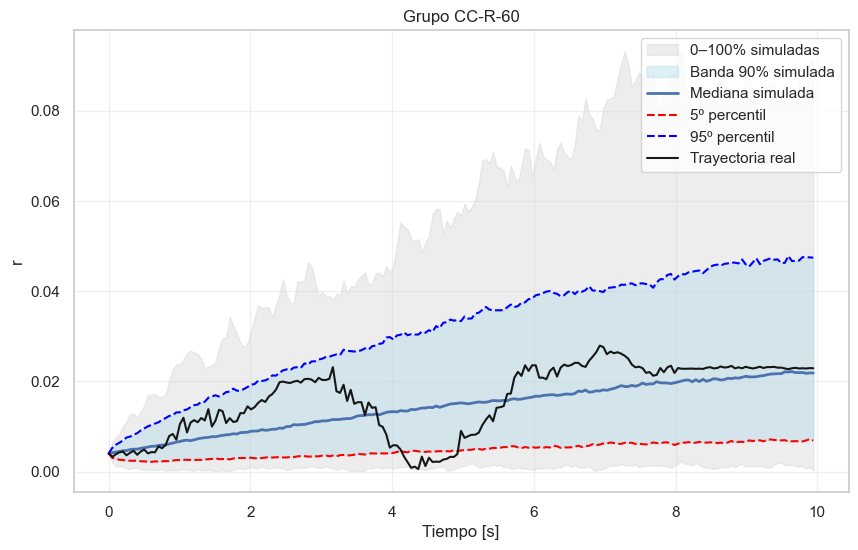

Grupo CC-R-60 - Porcentaje de tiempo dentro de la banda de 90%: 19.10%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-60 - ID-82.png


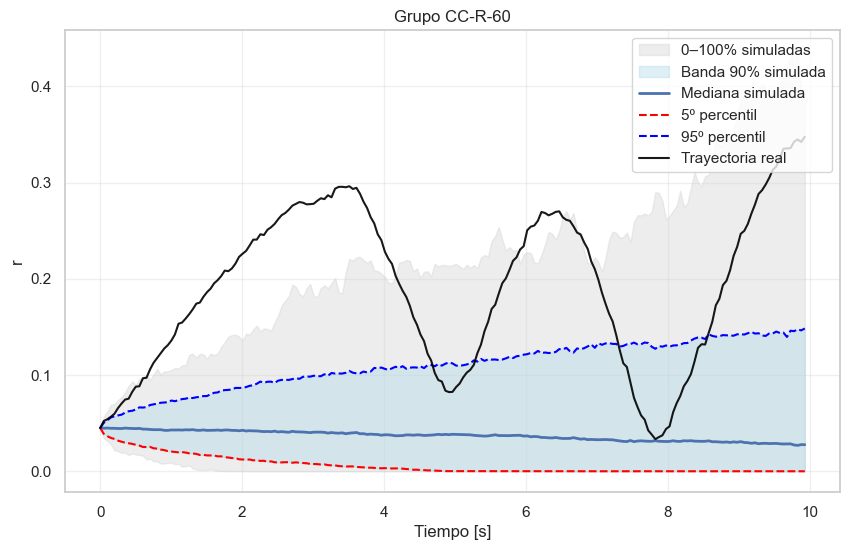

Grupo CC-R-60 - Porcentaje de tiempo dentro de la banda de 90%: 78.28%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-60 - ID-83.png


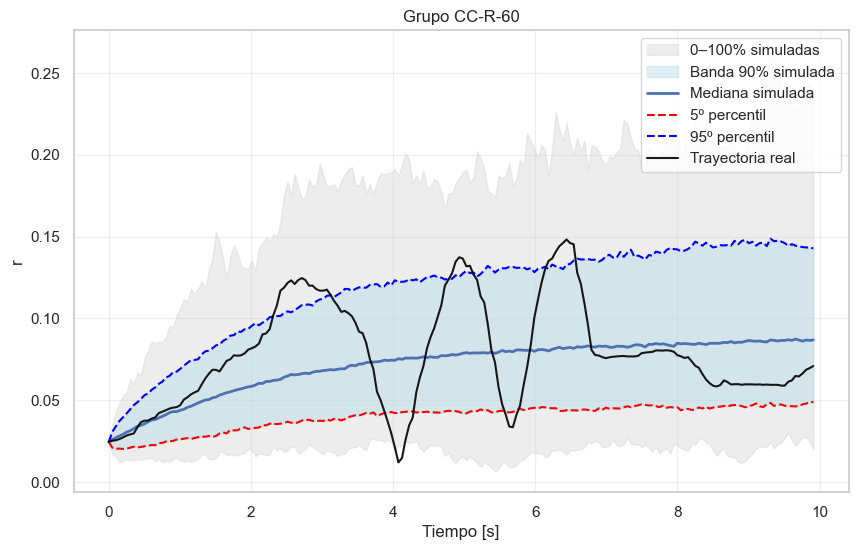

Grupo CC-R-20 - Porcentaje de tiempo dentro de la banda de 90%: 9.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-20 - ID-183.png


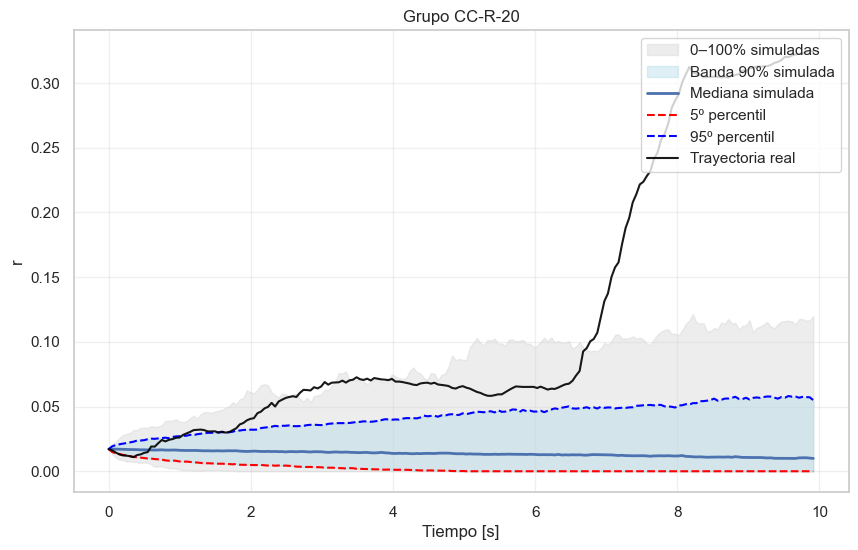

Grupo CC-R-20 - Porcentaje de tiempo dentro de la banda de 90%: 25.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-20 - ID-184.png


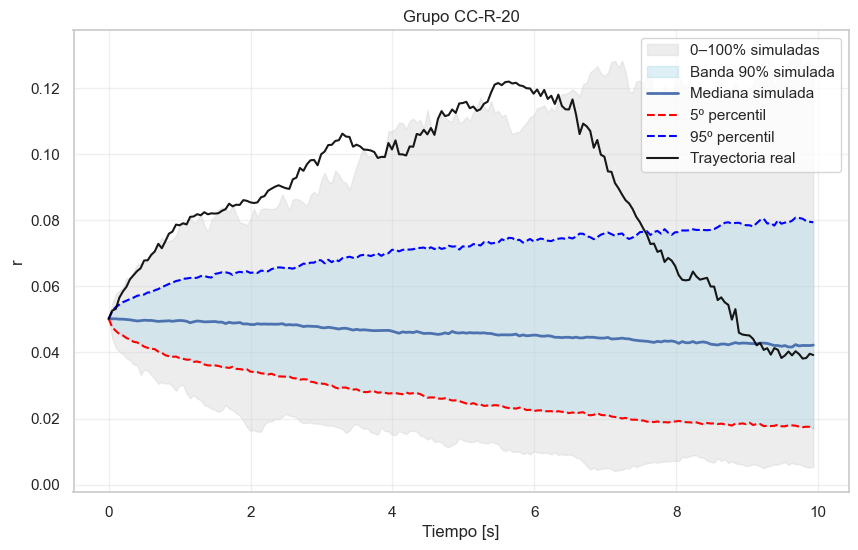

Grupo CC-R-20 - Porcentaje de tiempo dentro de la banda de 90%: 7.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-20 - ID-185.png


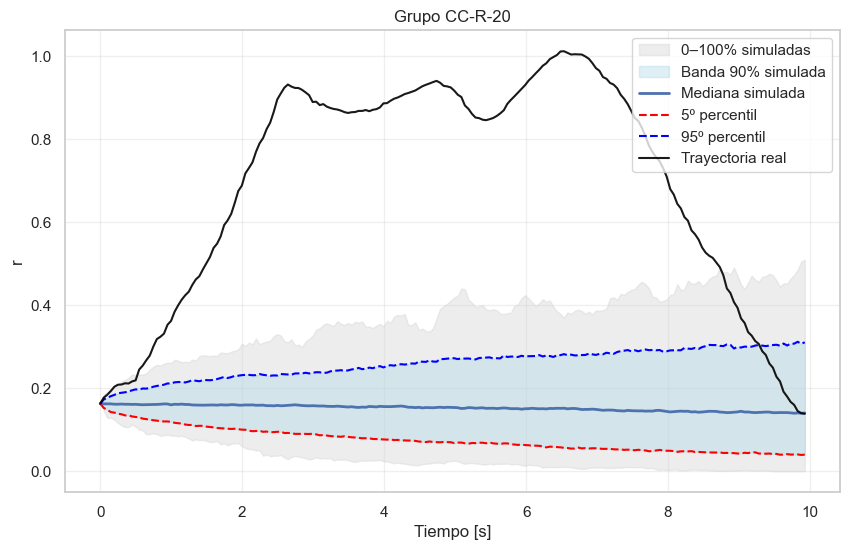

Grupo CC-R-20 - Porcentaje de tiempo dentro de la banda de 90%: 56.44%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-20 - ID-186.png


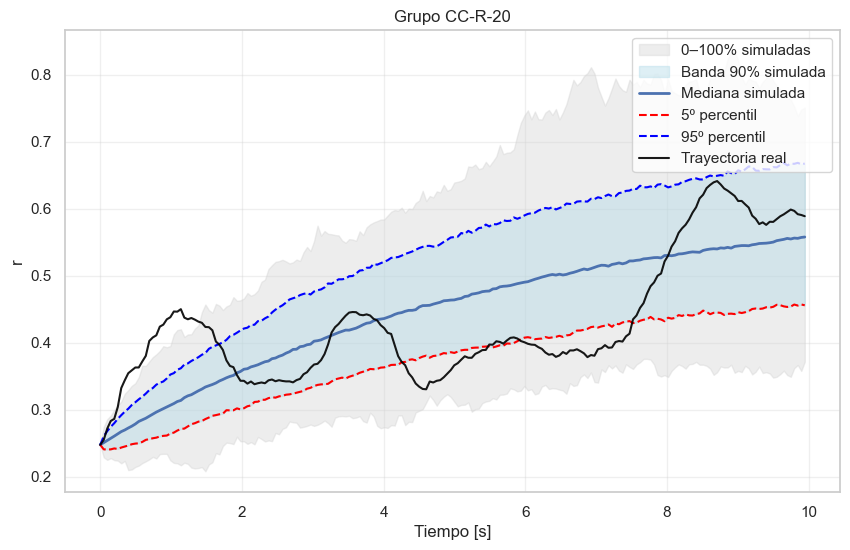

Grupo CC-R-20 - Porcentaje de tiempo dentro de la banda de 90%: 0.50%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-20 - ID-187.png


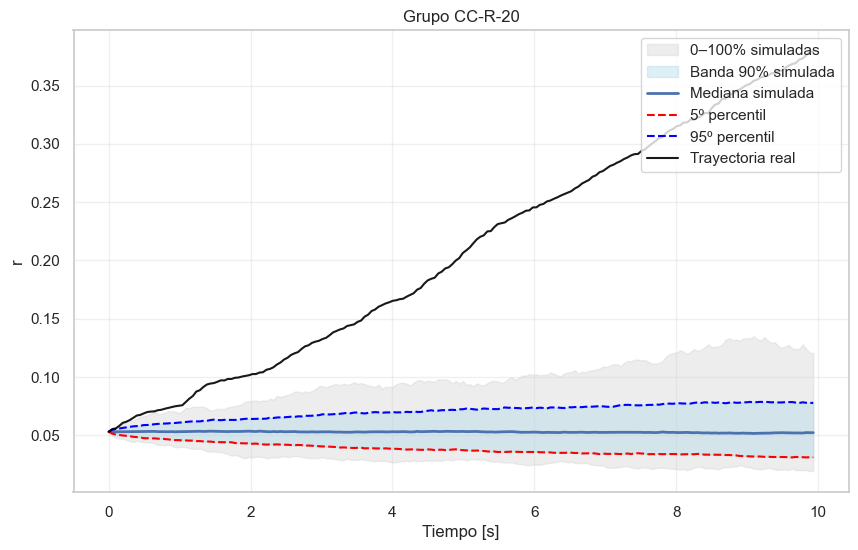

Grupo CC-R-20 - Porcentaje de tiempo dentro de la banda de 90%: 56.22%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-20 - ID-188.png


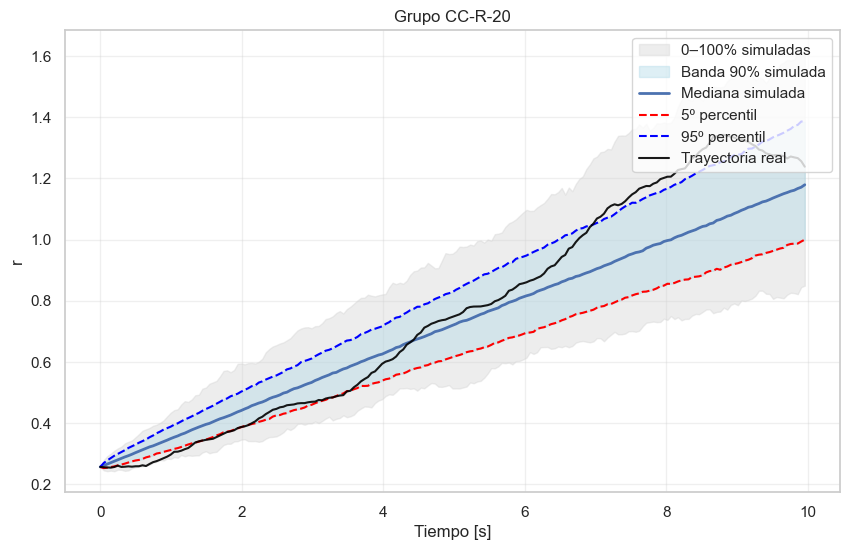

Grupo CC-R-25 - Porcentaje de tiempo dentro de la banda de 90%: 71.21%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-25 - ID-189.png


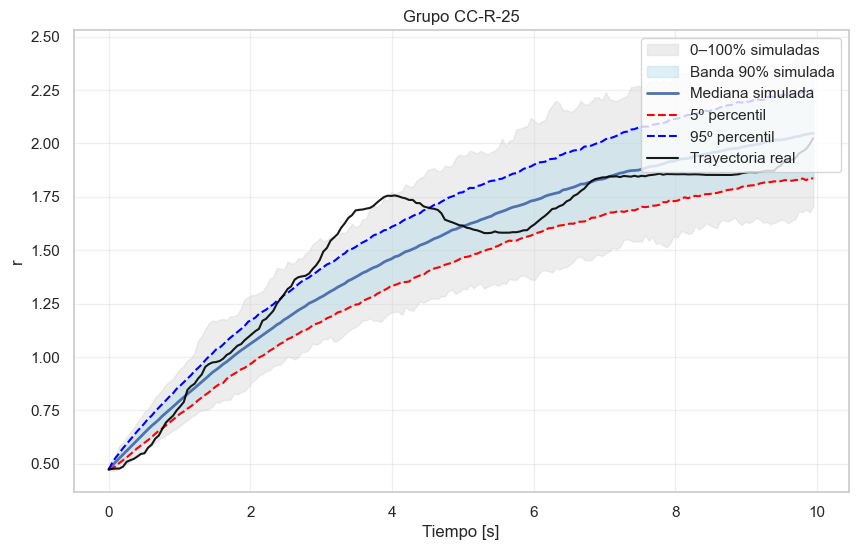

Grupo CC-R-25 - Porcentaje de tiempo dentro de la banda de 90%: 50.75%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-25 - ID-190.png


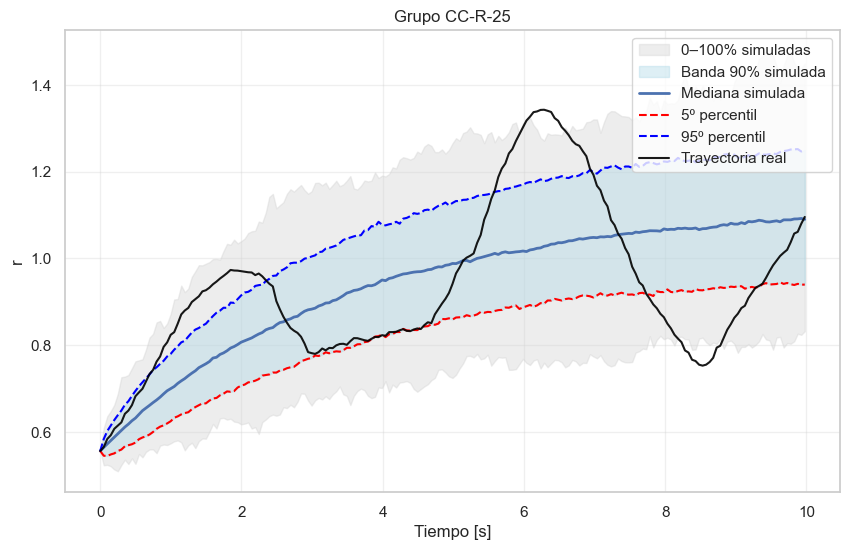

Grupo CC-R-25 - Porcentaje de tiempo dentro de la banda de 90%: 82.83%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-25 - ID-191.png


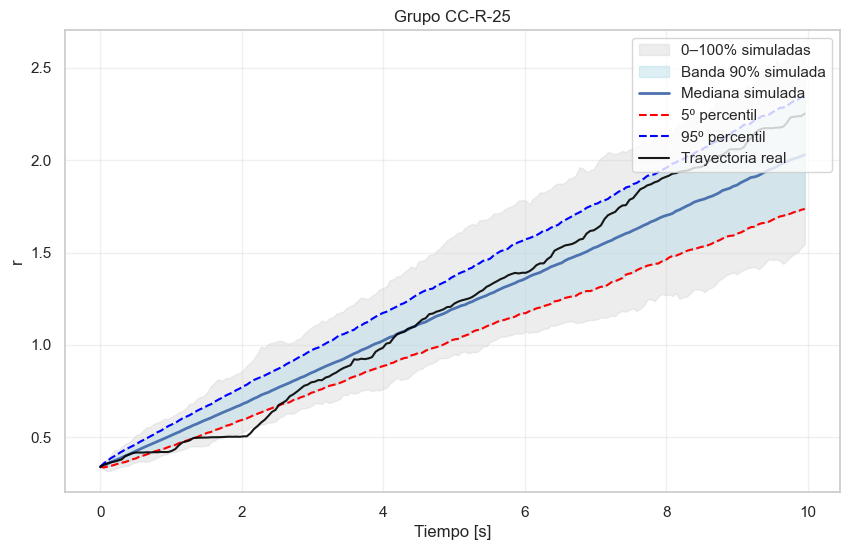

Grupo CC-R-25 - Porcentaje de tiempo dentro de la banda de 90%: 15.35%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-25 - ID-192.png


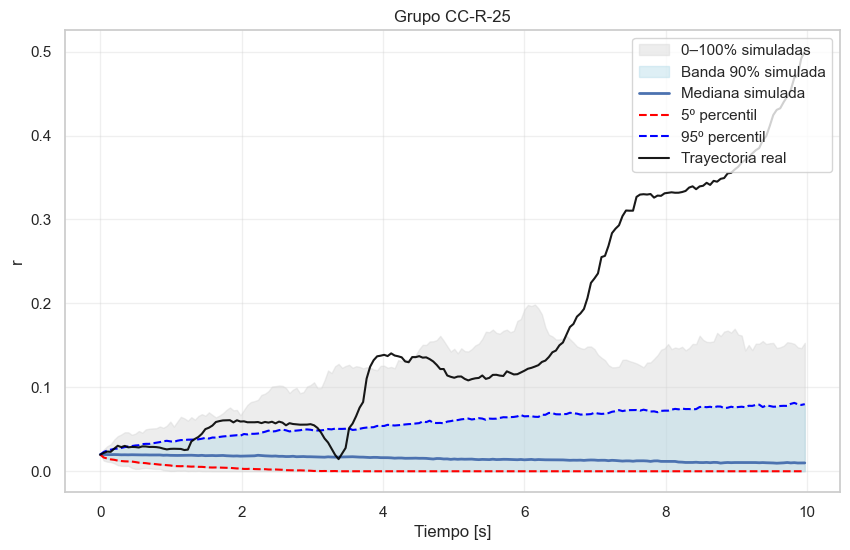

Grupo CC-R-25 - Porcentaje de tiempo dentro de la banda de 90%: 1.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-25 - ID-193.png


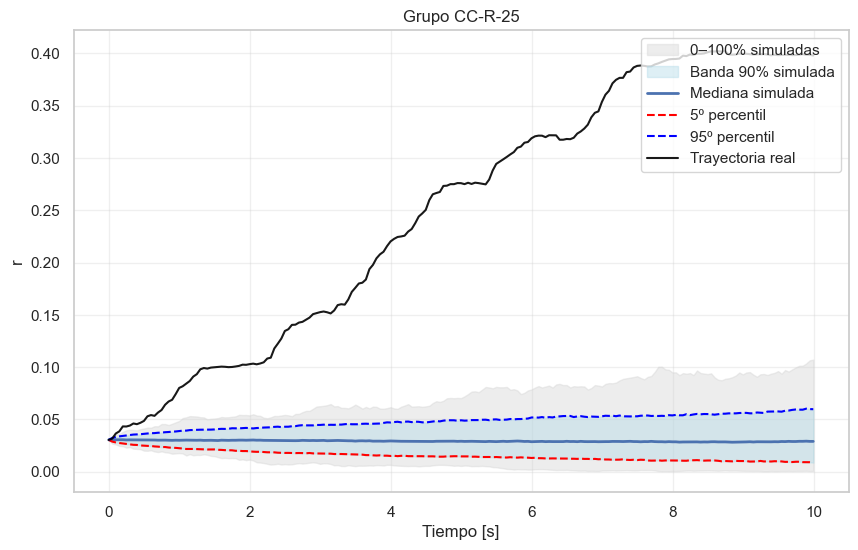

Grupo CC-R-25 - Porcentaje de tiempo dentro de la banda de 90%: 42.57%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-25 - ID-194.png


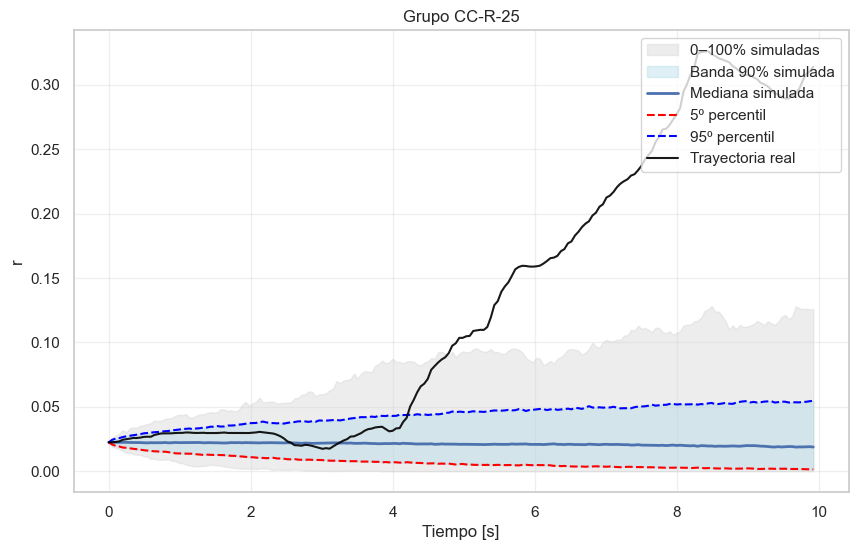

Grupo CC-R-30 - Porcentaje de tiempo dentro de la banda de 90%: 53.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-30 - ID-195.png


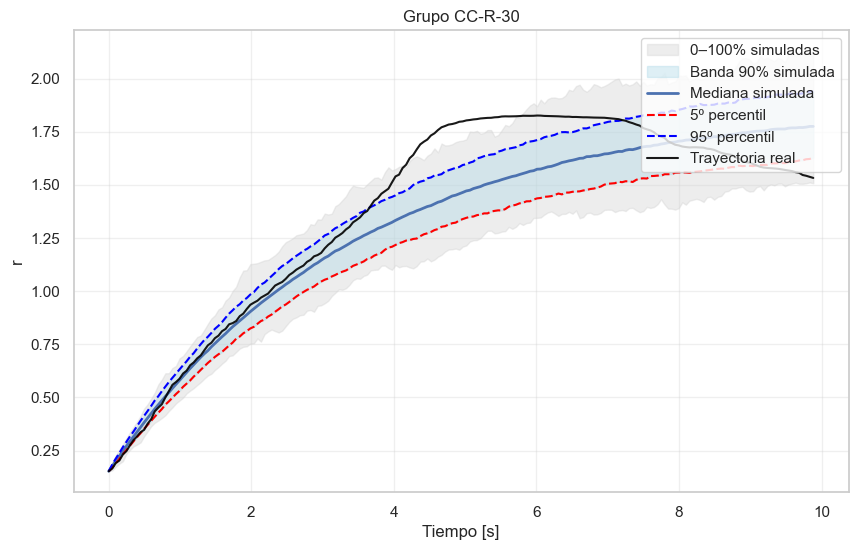

Grupo CC-R-30 - Porcentaje de tiempo dentro de la banda de 90%: 60.50%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-30 - ID-196.png


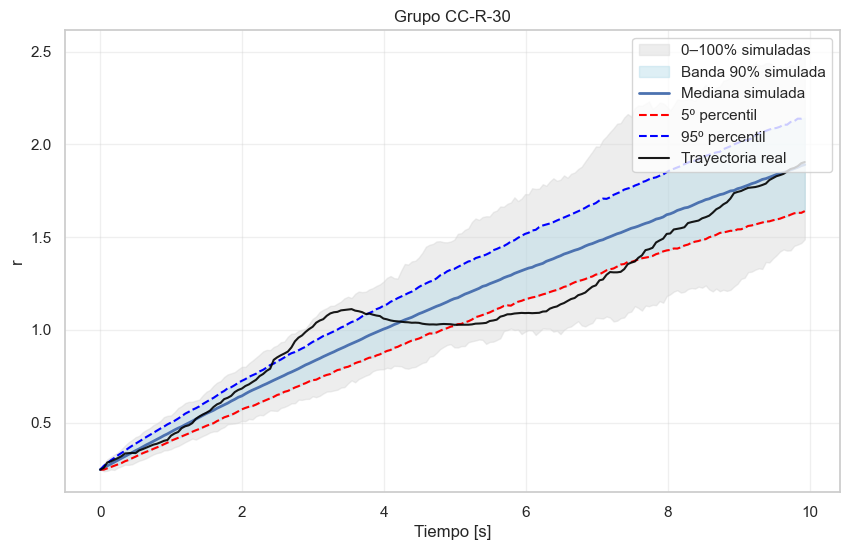

Grupo CC-R-30 - Porcentaje de tiempo dentro de la banda de 90%: 91.58%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-30 - ID-197.png


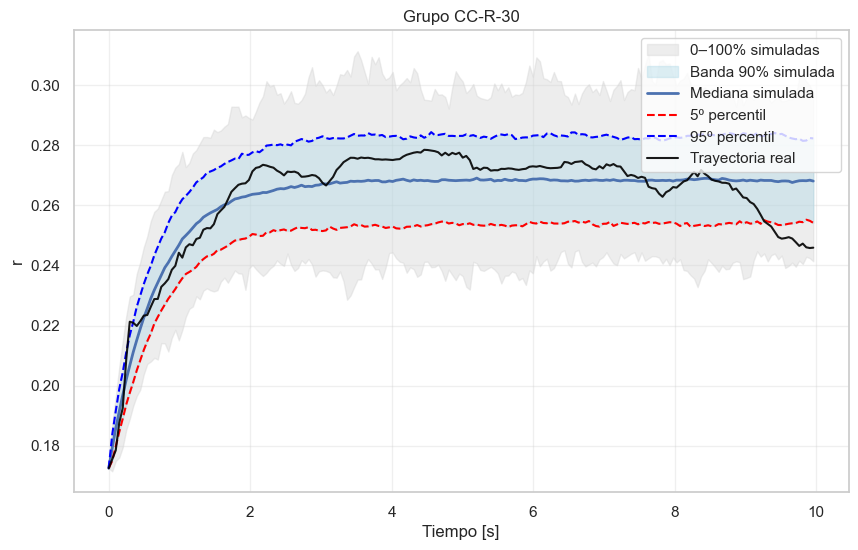

Grupo CC-R-30 - Porcentaje de tiempo dentro de la banda de 90%: 52.53%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-30 - ID-198.png


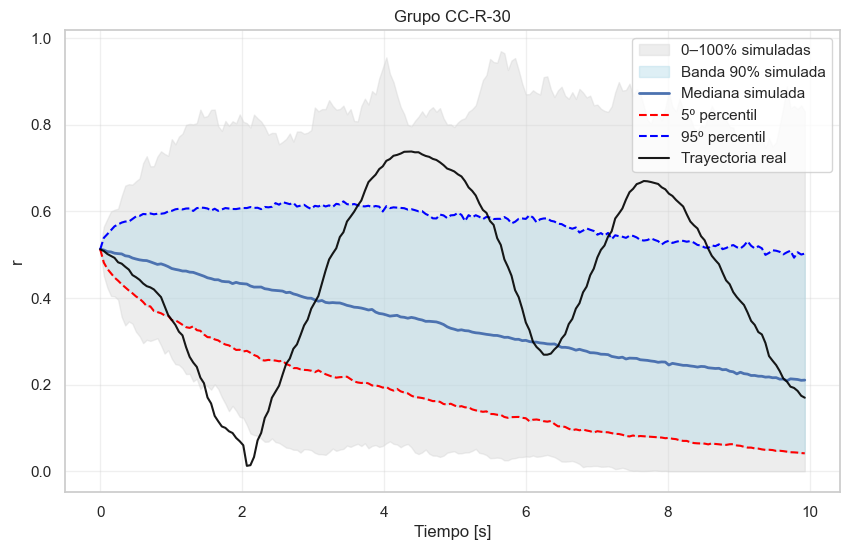

Grupo CC-R-30 - Porcentaje de tiempo dentro de la banda de 90%: 41.58%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-30 - ID-200.png


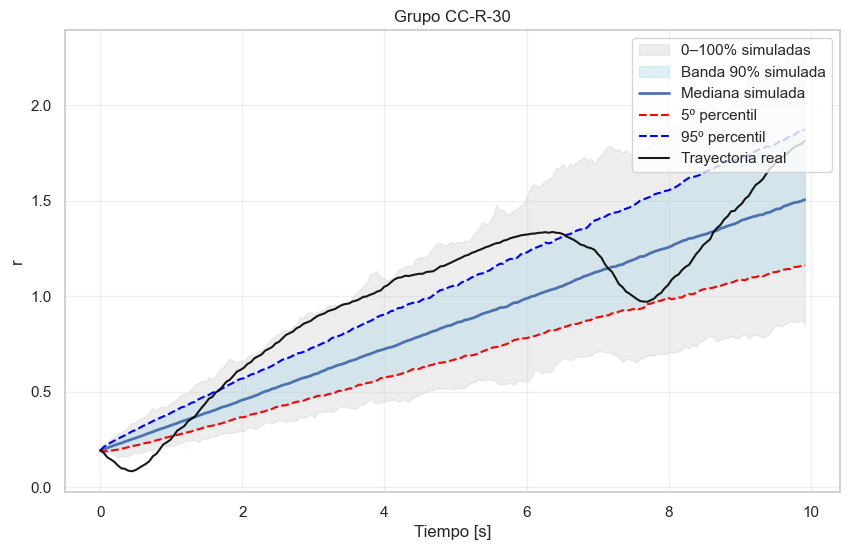

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 2.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-201.png


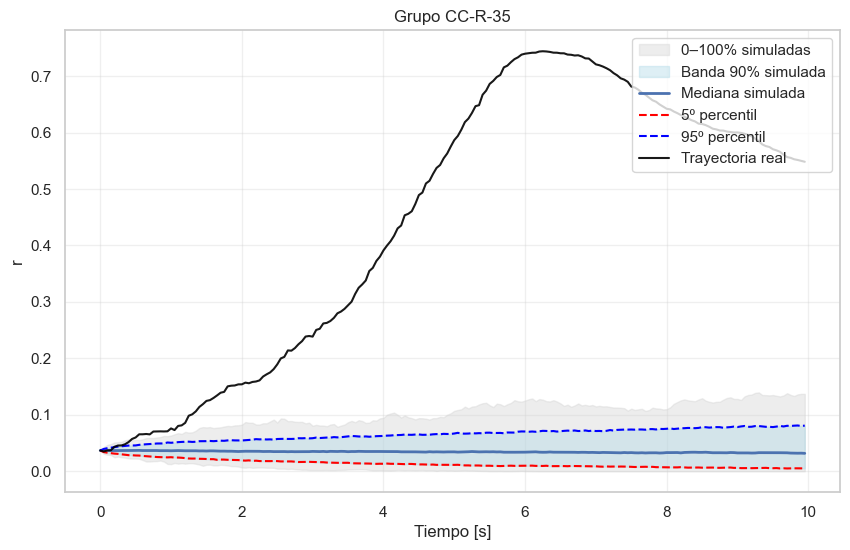

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 61.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-202.png


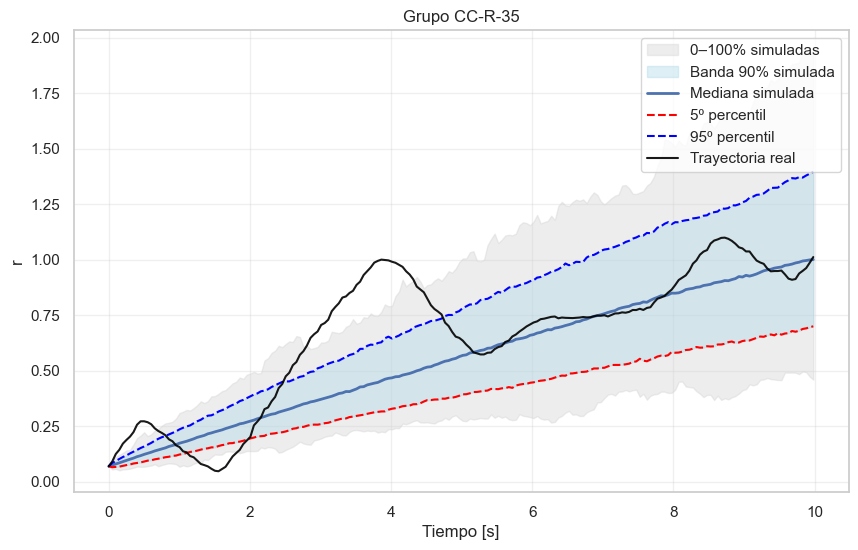

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 92.08%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-203.png


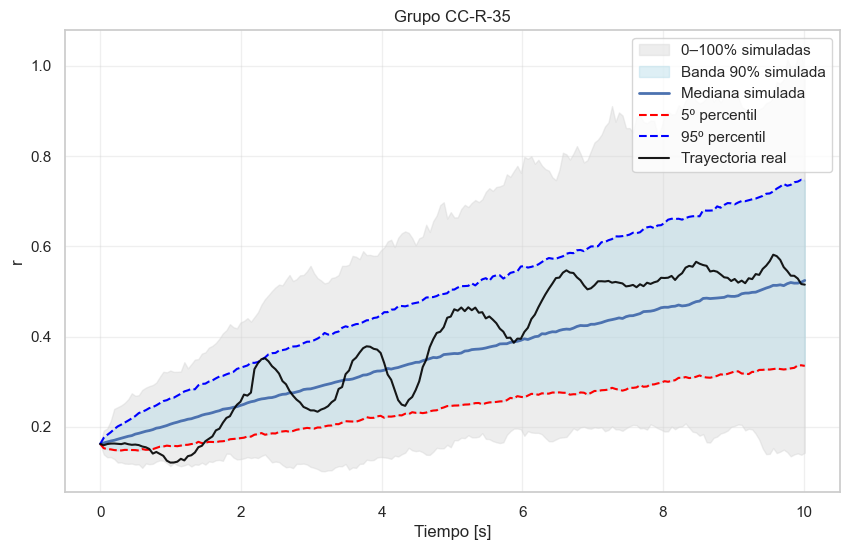

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 33.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-204.png


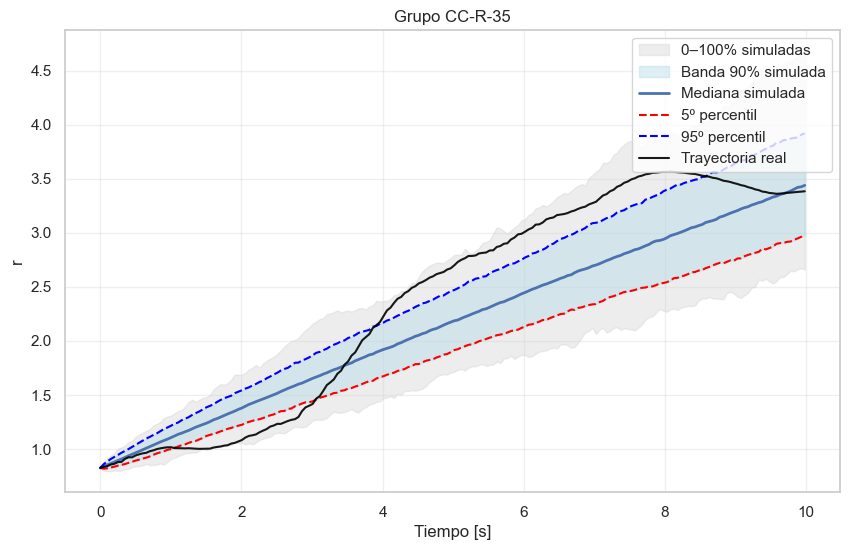

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 62.00%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-205.png


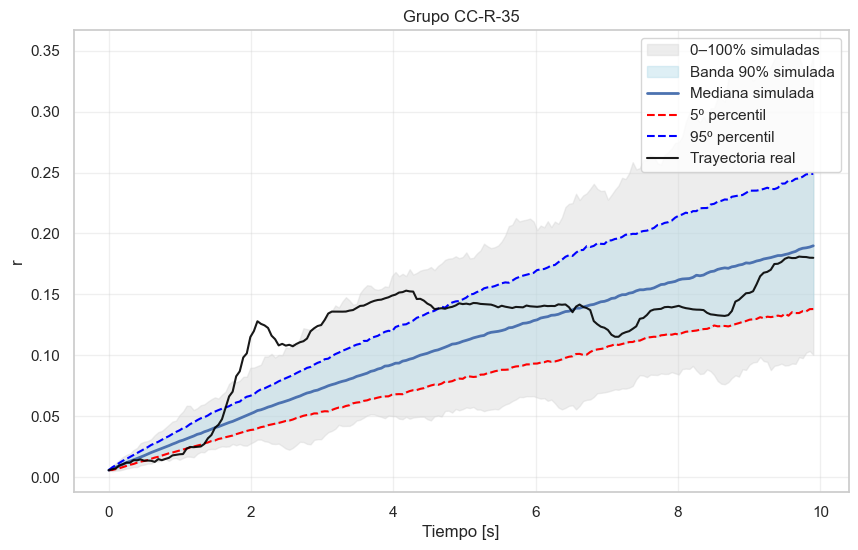

Grupo CC-R-35 - Porcentaje de tiempo dentro de la banda de 90%: 90.05%
Figura guardada en: C:\Users\franc\Desktop\Para informe\simulaciones_CIR_CC-R_FINAL\SIM_CC-R-35 - ID-206.png


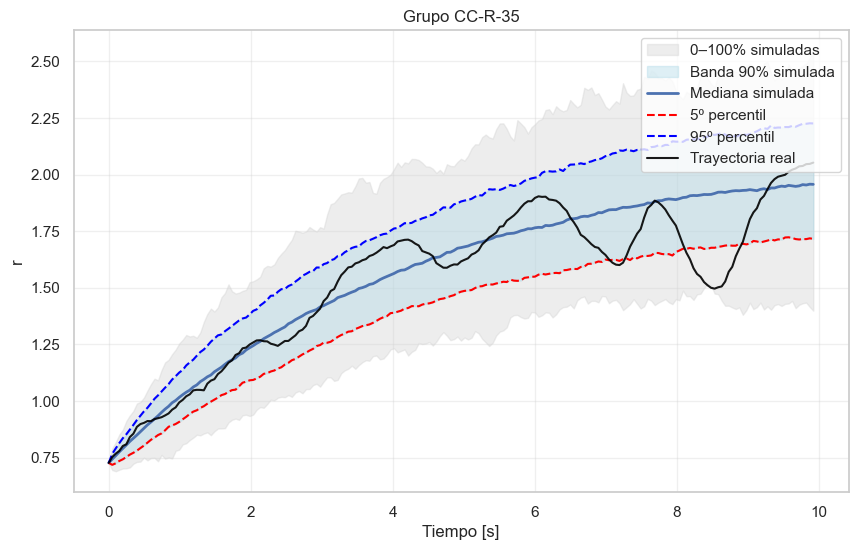

In [34]:
resultados_contencion = []

for index, fila in filtro.iterrows():
    
    id_actual = fila['id']
    
    if id_actual in trayectorias_all:
        trayectoria_real, dt_real = trayectorias_all[id_actual]
        porcentaje = evaluar_estimadores_CIR_paper_una_trayectoria(
            simular_CIR=simular_CIR,
            trayectoria=(trayectoria_real, dt_real),
            dt=dt_real,
            alpha=fila['alpha'],
            r_infinito=fila['mu'],
            sigma=fila['sigma'],
            variable=variable,
            especie=fila['grupo'].split('-')[0],
            tratamiento=fila['grupo'].split('-')[1],
            salinidad=fila['grupo'].split('-')[2],
            id_actual = fila['id'],
            M=1000
        )
        
        resultados_contencion.append({
            'id': id_actual,
            'grupo': fila['grupo'],
            'porcentaje_contencion': porcentaje,
            'salinidad': fila['salinidad']
        })
    else:
        print(f"Advertencia: No se encontró la trayectoria original para el ID {id_actual}.")
        
df_contencion = pd.DataFrame(resultados_contencion)

### Histograma de los porcentajes de este grupo

In [35]:
df_contencion['salinidad_ordenada'] = pd.Categorical(df_contencion['salinidad'], categories=orden_salinidad, ordered=True)
print(df_contencion)

     id      grupo  porcentaje_contencion salinidad salinidad_ordenada
0    42  CC-R-35-N              85.074627      35-N               35-N
1    43  CC-R-35-N              93.564356      35-N               35-N
2    45  CC-R-35-N              16.000000      35-N               35-N
3    46  CC-R-35-N              34.673367      35-N               35-N
4    48  CC-R-35-R              90.049751      35-R               35-R
5    50  CC-R-35-R              65.000000      35-R               35-R
6    51  CC-R-35-R               0.985222      35-R               35-R
7    52  CC-R-35-R              87.562189      35-R               35-R
8    53  CC-R-35-R              89.949749      35-R               35-R
9    54    CC-R-40              93.969849        40                 40
10   55    CC-R-40              79.000000        40                 40
11   57    CC-R-40              72.139303        40                 40
12   58    CC-R-40              81.094527        40                 40
13   5

In [36]:
paleta_colores

{'CC': '#0097b2',
 'LA': '#ffb039',
 'general': '#008fd6',
 'general2': '#009ead',
 'E': '#ff7f0e',
 'R': '#1f77b4'}

In [37]:
filtro

,id,alpha,mu,sigma,valor_funcion,exito,mensaje,r0,grupo,salinidad,salinidad_ordenada
0,42,4.952006e-01,4.099496e-02,0.066046,-865.621632,True,Optimization terminated successfully.,0.071869,CC-R-35-N,35-N,35-N
1,43,3.607137e-02,3.971088e-02,0.038007,-966.579560,True,Optimization terminated successfully.,0.011874,CC-R-35-N,35-N,35-N
2,45,1.150000e-10,9.750000e-11,0.063726,-745.082752,True,Optimization terminated successfully.,0.018991,CC-R-35-N,35-N,35-N
3,46,2.143573e-02,1.094494e-05,0.040605,-848.792353,True,Optimization terminated successfully.,0.126780,CC-R-35-N,35-N,35-N
4,48,2.707092e-01,4.552205e-02,0.077767,-816.102086,True,Optimization terminated successfully.,0.012293,CC-R-35-R,35-R,35-R
5,50,4.757879e-02,9.681821e-01,0.022493,-961.236327,True,Optimization terminated successfully.,0.118141,CC-R-35-R,35-R,35-R
6,51,1.000000e-10,1.000000e-10,0.028659,-871.241261,True,Optimization terminated successfully.,0.052971,CC-R-35-R,35-R,35-R
7,52,5.797367e-01,2.824205e-01,0.028046,-922.694735,True,Optimization terminated successfully.,0.164442,CC-R-35-R,35-R,35-R
8,53,6.631861e-02,5.031487e-01,0.154795,-538.825498,True,Optimization terminated successfully.,0.173656,CC-R-35-R,35-R,35-R
9,54,1.169360e-03,1.132447e+01,0.039117,-850.674025,False,Maximum number of function evaluations has bee...,0.155432,CC-R-40,40,40


Figura guardada en: C:\Users\franc\Desktop\Para informe\porcentajes_contencion\histograma_porcentajes_contencion_CIR.png
Figura guardada en: C:\Users\franc\Desktop\Para informe\porcentajes_contencion\boxplot_porcentaje_contencion_por_salinidad_CIR.png


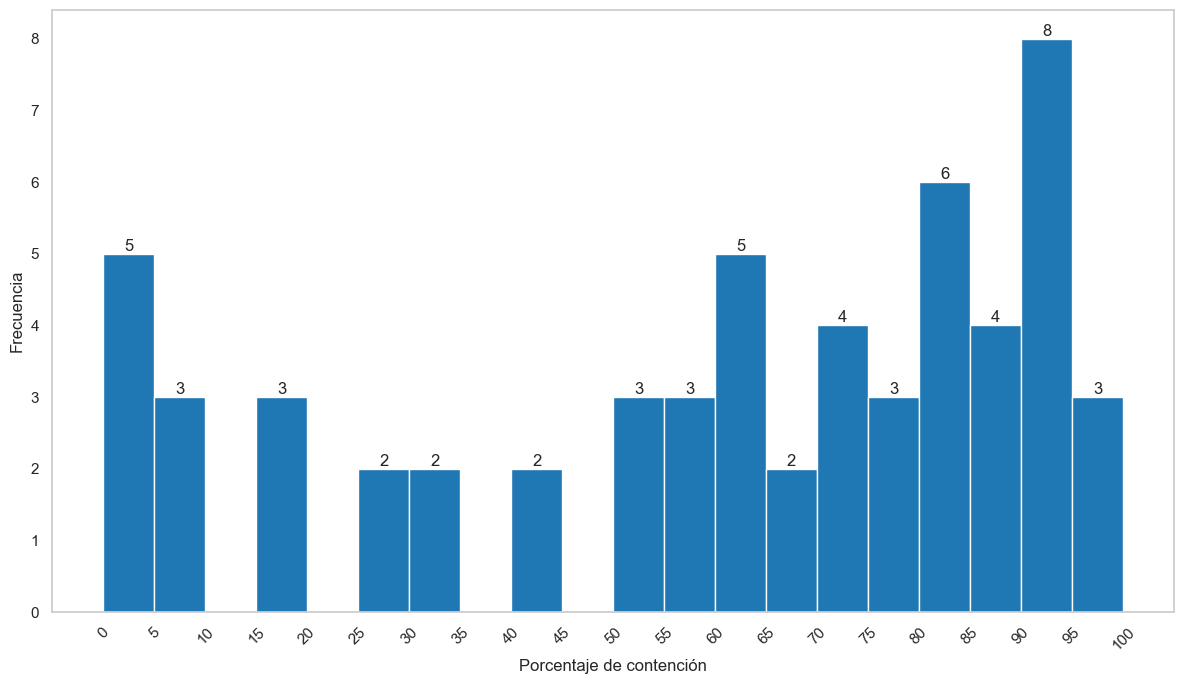

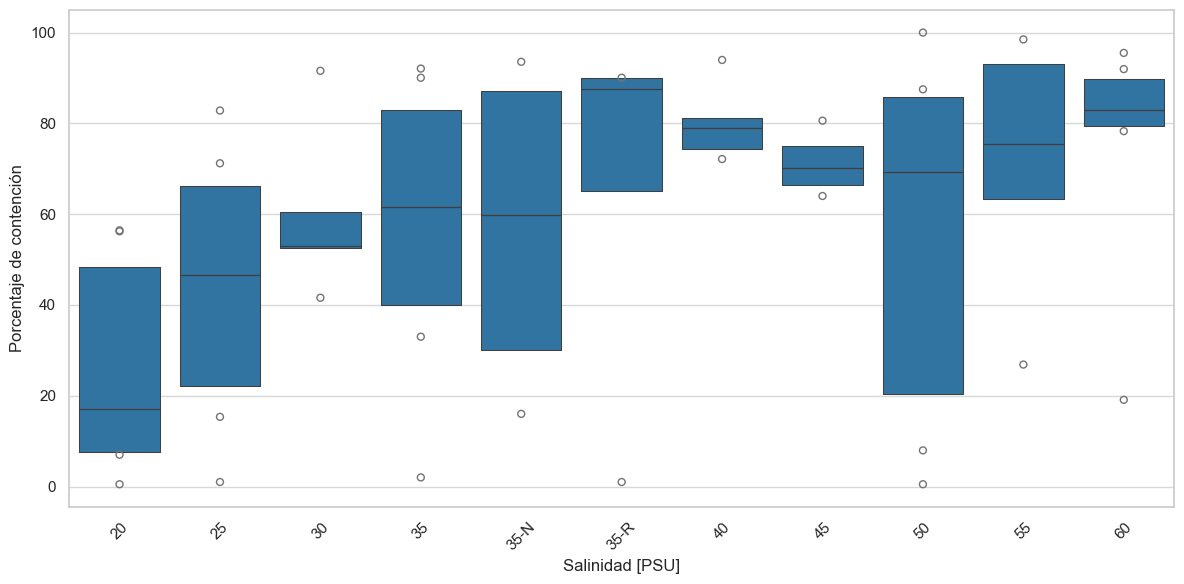

In [38]:
bins = np.arange(0, 105, 5) #o (0, 110, 10)

plt.figure(figsize=(12, 7))
counts, bins, patches = plt.hist(df_contencion['porcentaje_contencion'], bins=bins, color = paleta_colores['R'])

for count, patch in zip(counts, patches):
    if count > 0:
        plt.text(patch.get_x() + patch.get_width() / 2, count, int(count), ha='center', va='bottom')
plt.xlabel('Porcentaje de contención', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.xticks(bins, rotation=45)
plt.grid(visible=False)
plt.tight_layout()
guardar_figura('histograma_porcentajes_contencion_CIR', 'porcentajes_contencion')

plt.figure(figsize=(12, 6))
sns.boxenplot(data=df_contencion, x='salinidad_ordenada', y='porcentaje_contencion', color = paleta_colores['R'])
plt.xlabel('Salinidad [PSU]')
plt.ylabel('Porcentaje de contención')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
guardar_figura('boxplot_porcentaje_contencion_por_salinidad_CIR', 'porcentajes_contencion')
plt.show()

# De aquí pa abajo olvidar

In [39]:
contencion_buenos = df_contencion[df_contencion.porcentaje_contencion > 70]
contencion_buenos

print(len(df_contencion) - len(contencion_buenos)) #cuántos mueren

30


In [40]:
parametros_buenos = contencion_buenos.merge(filtro, how='left', on='id')
parametros_buenos

,id,grupo_x,porcentaje_contencion,salinidad_x,salinidad_ordenada_x,alpha,mu,sigma,valor_funcion,exito,mensaje,r0,grupo_y,salinidad_y,salinidad_ordenada_y
0,42,CC-R-35-N,85.074627,35-N,35-N,4.952006e-01,4.099496e-02,0.066046,-865.621632,True,Optimization terminated successfully.,0.071869,CC-R-35-N,35-N,35-N
1,43,CC-R-35-N,93.564356,35-N,35-N,3.607137e-02,3.971088e-02,0.038007,-966.579560,True,Optimization terminated successfully.,0.011874,CC-R-35-N,35-N,35-N
2,48,CC-R-35-R,90.049751,35-R,35-R,2.707092e-01,4.552205e-02,0.077767,-816.102086,True,Optimization terminated successfully.,0.012293,CC-R-35-R,35-R,35-R
3,52,CC-R-35-R,87.562189,35-R,35-R,5.797367e-01,2.824205e-01,0.028046,-922.694735,True,Optimization terminated successfully.,0.164442,CC-R-35-R,35-R,35-R
4,53,CC-R-35-R,89.949749,35-R,35-R,6.631861e-02,5.031487e-01,0.154795,-538.825498,True,Optimization terminated successfully.,0.173656,CC-R-35-R,35-R,35-R
5,54,CC-R-40,93.969849,40,40,1.169360e-03,1.132447e+01,0.039117,-850.674025,False,Maximum number of function evaluations has bee...,0.155432,CC-R-40,40,40
6,55,CC-R-40,79.000000,40,40,3.451346e-01,3.518990e-01,0.086133,-654.044522,True,Optimization terminated successfully.,0.057541,CC-R-40,40,40
7,57,CC-R-40,72.139303,40,40,1.230103e-01,1.680265e-02,0.039169,-1039.683977,True,Optimization terminated successfully.,0.018601,CC-R-40,40,40
8,58,CC-R-40,81.094527,40,40,1.908725e-04,5.942013e+01,0.071270,-736.670364,False,Maximum number of function evaluations has bee...,0.008697,CC-R-40,40,40
9,59,CC-R-40,74.371859,40,40,3.306107e-01,2.948947e-01,0.260637,-294.618053,True,Optimization terminated successfully.,1.117467,CC-R-40,40,40


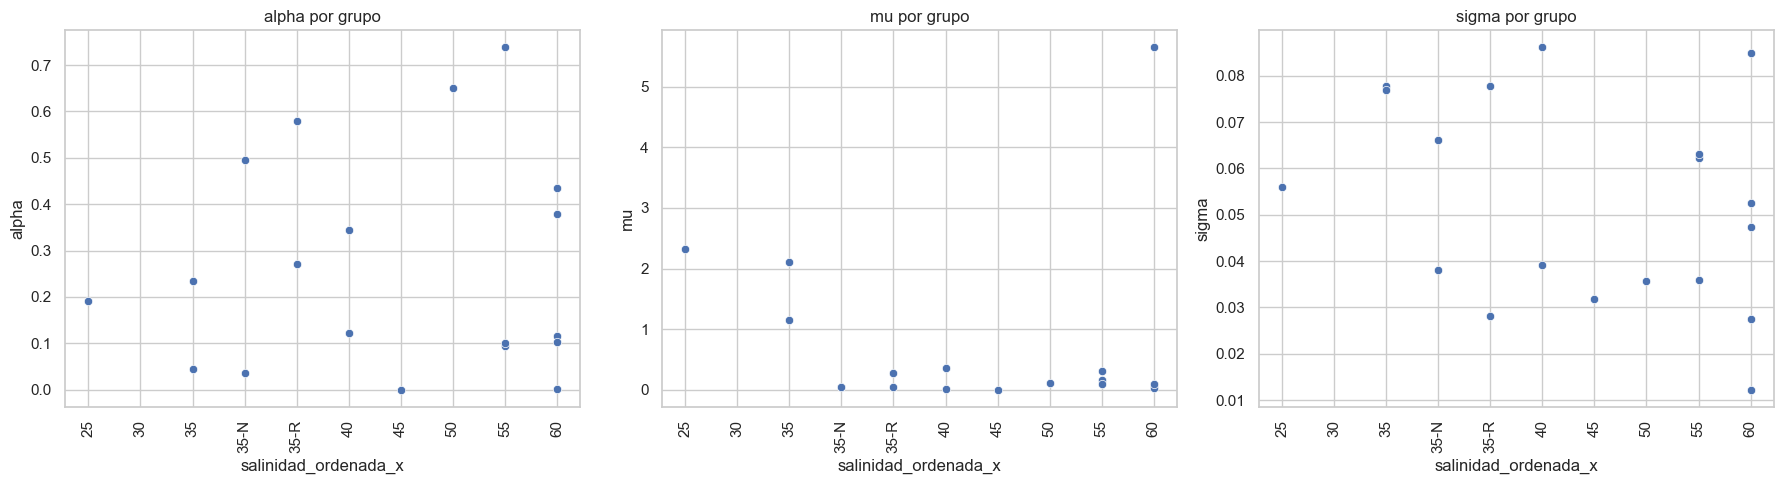

In [41]:
filtro_sin_outliers2 = filtrar_outliers_IQR(parametros_buenos, ['alpha', 'mu', 'sigma'])
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

#alpha
sns.scatterplot(data=filtro_sin_outliers2, x='salinidad_ordenada_x', y='alpha', ax=axs[0])#, hue = 'mejor_por_logL')
axs[0].set_title('alpha por grupo')
axs[0].set_ylabel('alpha')

#mu
sns.scatterplot(data=filtro_sin_outliers2, x='salinidad_ordenada_x', y='mu', ax=axs[1])#, hue = 'mejor_por_logL')
axs[1].set_title('mu por grupo')
axs[1].set_ylabel('mu')

#sigma
sns.scatterplot(data=filtro_sin_outliers2, x='salinidad_ordenada_x', y='sigma', ax=axs[2])#, hue = 'mejor_por_logL')
axs[2].set_title('sigma por grupo')
axs[2].set_ylabel('sigma')

axs[0].tick_params(axis='x', rotation=90)
axs[1].tick_params(axis='x', rotation=90)
axs[2].tick_params(axis='x', rotation=90)

plt.tight_layout()
#guardar_figura(f'parametros-{grupo}', 'plot_parametros_CIR')
plt.show()

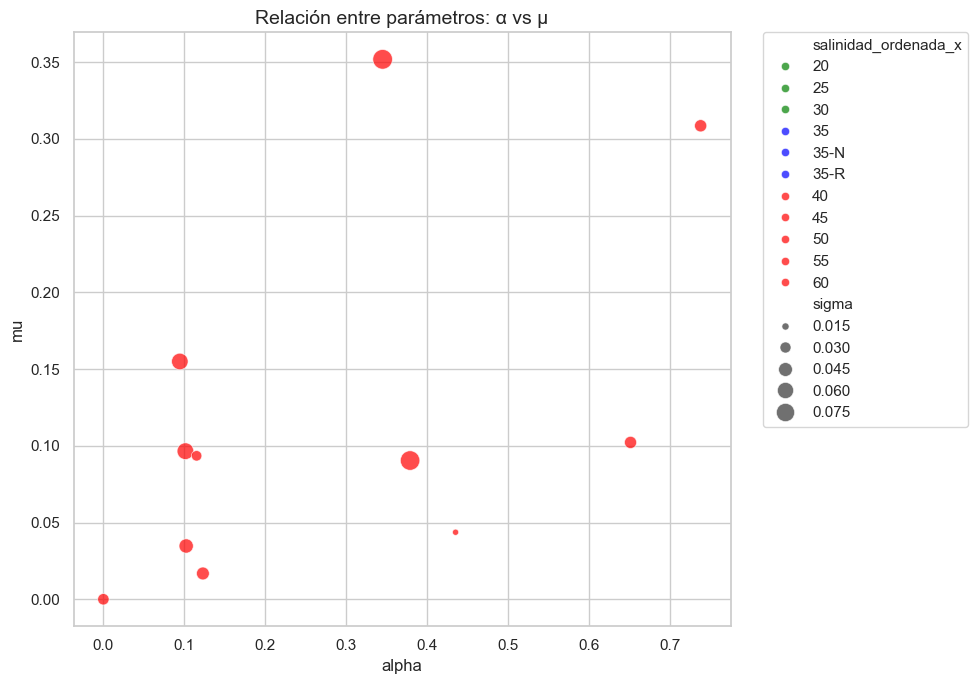

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

filtrofinal2 = filtro_sin_outliers2[~filtro_sin_outliers2['salinidad_x'].isin(['35', '35-N', '35-R'])]
filtrofinal2 = filtrar_outliers_IQR(filtrofinal2, ['alpha', 'mu', 'sigma'])


# Configuración de estilo
sns.set(style="whitegrid")
paleta_salinidad = {
    "35-N": "blue",
    "35-R": "blue",
    "35": "blue",
    "20": "green",
    "25": "green",
    "30": "green",
    "40": "red",
    "45": "red",
    "50": "red",
    "55": "red",
    "60": "red"
}
# Gráfico de dispersión
plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(
    data=filtrofinal2,
    x="alpha",
    y="mu",
    hue="salinidad_ordenada_x",       # Color por salinidad
    size="sigma",          # Tamaño proporcional a sigma,         # Forma del marcador según éxito
    sizes=(20, 200),       # Rango de tamaños de puntos
    alpha=0.7,
    palette=paleta_salinidad
)

# Ajustes de leyenda y título
plt.title("Relación entre parámetros: α vs μ", fontsize=14)
plt.xlabel("alpha", fontsize=12)
plt.ylabel("mu", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)  # leyenda afuera
plt.tight_layout()
plt.show()
